<div style="display: flex; background-color: RGB(0, 80, 239);" >
<h1 style="margin: auto; padding: 30px; ">ETUDE DE MARCHE CHEZ "LA POULE QUI CHANTE" <br> <p style="text-align:center; padding: 15px;"> Partie I - Prépare et nettoie les données </h1>
</div>

# L'objective
L'objectif de ce travail est de analyse des groupements de pays que l’on peut cibler pour exporter nos poulets

Ce premier notebook sert à 
- importer,
- nettoyer,
- fusionner les données 
- explorer et analyser la distribution de chaque variable et les valeurs aberrantes potentielles

pour disposer d'un ensemble de données complet pouvant être utilisé dans l'analyse statistique multivariée.




Dans l'ensemble de données final, huit variables sont prises en compte:
1. Population (taille de marché)
2. Gross National Income GNI (pouvoir d'achat)
3. Consommation de volaille (préférences alimentaires)
[Élevé : aliments populaires, marché existant / Faible : marché à croissance potentielle, mais acceptation incertaine]
4. Trend de consommation, ou croissance de demande de volaille (dynamique de la demande de voilaille)
5. Dépendance aux importations DIR (opportunités commerciales)
 [0 : autosuffisant / > 0 : dépendant des importations / < 0 : exportateur]                 
6. Distance au Paris (couts commercieaux, et empreinte écologique)                                 
7. Indicateur population urbaine (proxy de la demande de produits biologiques)
8. Logistic Performance Index LPI (infrastructures et couts coommerciaux)

<div style="background-color: RGB(27, 161, 226);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des jeux des données</h2>
</div>

<div style="border: 2px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">1.1 - Importation des librairies</h3>
</div>

In [39]:
# importation des  librairies
import os
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import unicodedata
from geopy.distance import geodesic
from rapidfuzz import process


In [17]:
#%pip install requests pandas


In [18]:
#%pip install geopy pandas


In [19]:
#%pip install rapidfuzz

In [20]:
#%pip install rapidfuzz requests pandas

<div style="border: 2px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">1.2 - Chargement des jeux de données</h3>
</div>

In [21]:
# acceder au "working directory" dans le dossier "Donnees" pour avoir le nom de fichier
os.listdir("Donnees")

['df_multi_log.csv',
 'df_multi_red.csv',
 'DisponibiliteAlimentaire_2010_2017.csv',
 'DisponibiliteAlimentaire_2017.csv',
 'geo_cepii.csv',
 'GNI_per_capita_worldbank.csv',
 'Logistic_peformance_index_worldbank_FR.csv',
 'Population_2000_2018.csv',
 'Urban_share_worldbank_FR.csv']

In [49]:
# Importation du fichier Population_2000_2018
df_pop = pd.read_csv("Donnees/Population_2000_2018.csv")

In [71]:
# Importation du fichier DisponibiliteAlimentaire_2017
df_disp = pd.read_csv("Donnees/DisponibiliteAlimentaire_2017.csv")

In [24]:
# Importation du fichier DisponibiliteAlimentaire_2010_2017
df_disp_2010_17 = pd.read_csv("Donnees/DisponibiliteAlimentaire_2010_2017.csv")

In [27]:
import time

for i in range(3):
    response = requests.get(url)
    
    if response.status_code == 200:
        try:
            data = response.json()[1]
            break
        except:
            print("Invalid JSON, retrying...")
    else:
        print("Status:", response.status_code)
    
    time.sleep(2)

In [29]:
# Importation du fichier GNI per capita directment depuis l'API de la Banque Mondiale
import requests

url = "https://api.worldbank.org/v2/fr/country/all/indicator/NY.GNP.PCAP.CD?date=2017&per_page=20000&format=json"

response = requests.get(url)
data = response.json()[1]

df_GNI = pd.json_normalize(data)
df_GNI = df_GNI[["country.id","country.value","value","date"]]
df_GNI.columns = ["country_code","country","GNI_per_capita","year"]

# Correction de l'ensemble de données : deux noms de pays sont manquants
mask = df_GNI["country_code"] == "ZH"
df_GNI.loc[mask,"country"] = "Afrique orientale et méridionale" # ZH

mask = df_GNI["country_code"] == "ZI"
df_GNI.loc[mask,"country"] = "Afrique occidentale et centrale" # ZI


In [30]:
# Importation du fichier de geolocalisation des pays (database principale pour )
df_geo = pd.read_csv("Donnees/geo_cepii.csv")

# https://cepii.fr/CEPII/en/bdd_modele/bdd_modele_item.asp?id=6

In [31]:
# Importation du fichier de Proportion de population urbaine
df_urb = pd.read_csv("Donnees/Urban_share_worldbank_FR.csv")

# https://data.worldbank.org/indicator/SP.URB.TOTL.IN.ZS?end=2024&start=1960&view=chart

In [32]:
# Importation du fichier de Logistic Performance Index (LPI)
df_LPI = pd.read_csv("Donnees/Logistic_peformance_index_worldbank_FR.csv")

# https://data.worldbank.org/indicator/LP.LPI.OVRL.XQ

<div style="background-color: RGB(27, 161, 226);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des jeux des données</h2>
</div>

In [56]:
# Créer une fonction qui normalise les noms de pays dans les jeux de données, afin de faciliter les fusions (merge) plus tard dans le script
def normalize(text):
    text = text.lower()
    text = unicodedata.normalize('NFKD', text)
    return text.encode('ascii', 'ignore').decode('utf-8')


In [55]:
# Fonction qui ajoutera le code pays ISO 3 normalisé à un ensemble de données, ainsi que les pays qui n'ont pas encore été appariés


def match_countries_to_iso3(df, country_col, threshold=80):
    """
    Associe les noms de pays (français) aux codes ISO3 en utilisant la référence de la Banque mondiale + fuzzy matching
    
    parametres:
    - df: input dataframe
    - country_col: column name with country names
    - threshold: matching score threshold (0–100)
    
    Returns:
    - df with added columns: country_matched, iso3
    - unmatched dataframe
    """

    # --- 1. Obtenir une référence de la Banque mondiale (noms français + ISO3)
    url = "https://api.worldbank.org/v2/fr/country?per_page=400&format=json"
    response = requests.get(url)
    data = response.json()[1]

    ref = pd.json_normalize(data)
    ref = ref[["id", "name"]]
    ref["name_norm"] = ref["name"].apply(normalize)
    ref.columns = ["iso3", "country_fr","country_norm_fr"]

    reference_names = ref["country_norm_fr"].tolist()

    # --- 2. Fonction de correspondance
    def match_name(name):
        match, score, _ = process.extractOne(name, reference_names)
        if score >= threshold:
            return match
        else:
            return None

    # --- 3. Appliquer la correspondance
    df = df.copy()
    df["country_matched"] = df[country_col].apply(match_name)

    # --- 4. Fusionnez pour obtenir l'ISO3
    df = df.merge(ref, left_on="country_matched", right_on="country_norm_fr", how="left")

    # --- 5. Identifier les éléments non appariés
    unmatched = df[df["iso3"].isna()][[country_col]].drop_duplicates()

    return df, unmatched

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.1 - Analyse du fichier Population (df_pop), variable: Population </h3>
</div>

In [50]:
# Afficher des 5 premières lignes du dataset
df_pop.head(3)


,Code Domaine,Domaine,Code zone,Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole,Note
0,OA,Séries temporelles annuelles,2,Afghanistan,511,Population totale,3010,Population-Estimations,2000,2000,1000 personnes,20779.953,X,Sources internationales sûres,NaN
1,OA,Séries temporelles annuelles,2,Afghanistan,511,Population totale,3010,Population-Estimations,2001,2001,1000 personnes,21606.988,X,Sources internationales sûres,NaN
2,OA,Séries temporelles annuelles,2,Afghanistan,511,Population totale,3010,Population-Estimations,2002,2002,1000 personnes,22600.770,X,Sources internationales sûres,NaN


In [51]:
# information générale sur ce dataset
print("Nombre des observations:",df_pop.shape[0])
print("Nombre des variables:",df_pop.shape[1])
print()
print("Nombre des lignes dupliquées:",df_pop.duplicated().sum())
print()
print("Dèja, un peut constate que il n'y a pas de NaN (voir ci-dessous) et pas des lignes doublons (voir ci-dessus) dans ce dataset:")
print()
print()
df_pop.info()

Nombre des observations: 4411
Nombre des variables: 15

Nombre des lignes dupliquées: 0

Dèja, un peut constate que il n'y a pas de NaN (voir ci-dessous) et pas des lignes doublons (voir ci-dessus) dans ce dataset:


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4411 entries, 0 to 4410
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Code Domaine            4411 non-null   object 
 1   Domaine                 4411 non-null   object 
 2   Code zone               4411 non-null   int64  
 3   Zone                    4411 non-null   object 
 4   Code Élément            4411 non-null   int64  
 5   Élément                 4411 non-null   object 
 6   Code Produit            4411 non-null   int64  
 7   Produit                 4411 non-null   object 
 8   Code année              4411 non-null   int64  
 9   Année                   4411 non-null   int64  
 10  Unité                   4411 non-nu

In [52]:
# Créer une nouvelle colonne avec un nom de pays normalisé pour faciliter les fusions (merge) plus tard dans le script
df_pop.insert(loc = 0,
          column = "pays_norm",
          value = df_pop["Zone"].apply(normalize))

In [53]:
# Reduir le dataset pour les lignes (années 2017) et les colonnes d'intérêt (Zone et Valeur de population)
mask = df_pop["Année"] == 2017
df_pop_2017 = df_pop.loc[mask,["pays_norm","Zone","Valeur"]]
df_pop_2017["Valeur"] = df_pop_2017["Valeur"] * 1000  # "Valeur" est exprimée en 1000 personnes, convertire a nombre de personnes
df_pop_2017["log_population"] = np.log(df_pop_2017["Valeur"]) # La distribution de la population est fortement asymétrique, une transformation logarithmique pour de meilleurs résultats dans l'analyse ACP 
df_pop_2017.rename(columns={"Code zone":"pays_code","Zone":"pays","Valeur":"population"}, inplace=True) # Renommer les colonnes pour faciliter la compréhension
pop_total_2017 = df_pop_2017["population"].sum() # calcule la population mondial en 2017

print("Nombre des observations:",df_pop_2017.shape[0])
print("Nombre des pays unique:",df_pop_2017["pays"].nunique())
print("Nombre des variables:",df_pop_2017.shape[1])
df_pop_2017.head(5)

Nombre des observations: 236
Nombre des pays unique: 236
Nombre des variables: 4


,pays_norm,pays,population,log_population
17,afghanistan,Afghanistan,36296113.0,17.407221
36,afrique du sud,Afrique du Sud,57009756.0,17.858733
55,albanie,Albanie,2884169.0,14.874747
74,algerie,Algérie,41389189.0,17.538530
93,allemagne,Allemagne,82658409.0,18.230227


In [57]:
# Ajouter le code pays ISO 3 à l'ensemble de données, en utilisant le nom de pays normalisé:
df_clean, unmatch = match_countries_to_iso3(df_pop_2017, "pays_norm", threshold=80)

In [58]:
# Rechercher les erreurs
print(unmatch) # unmatch
# df_clean[df_clean["iso3"].duplicated(False)] # duplicats de iso3

                               pays_norm
7                               anguilla
9            antilles neerlandaises (ex)
79                            guadeloupe
116                         kirghizistan
135                           martinique
138                              mayotte
144                           montserrat
153                                nioue
162                            palestine
183                              reunion
187                    sahara occidental
188                     saint-barthelemy
194             saint-pierre-et-miquelon
195                          saint-siege
205  sint maarten  (partie neerlandaise)
221                             tokelaou


In [59]:
# Corrections de l'ISO3 dans l'ensemble de données df_pop_2017
# unmatch
df_clean.loc[(df_clean["pays"] == "Anguilla"),"iso3"] = "AIA"
df_clean.loc[(df_clean["pays"] == "Antilles néerlandaises (ex)"),"iso3"] = "ANT"
df_clean.loc[(df_clean["pays"] == "Bonaire, Saint-Eustache et Saba"),"iso3"] = "BES"
df_clean.loc[(df_clean["pays"] == "Guadeloupe"),"iso3"] = "GLP"
df_clean.loc[(df_clean["pays"] == "Kirghizistan"),"iso3"] = "KGZ"
df_clean.loc[(df_clean["pays"] == "Martinique"),"iso3"] = "MTQ"
df_clean.loc[(df_clean["pays"] == "Mayotte"),"iso3"] = "MYT"
df_clean.loc[(df_clean["pays"] == "Montserrat"),"iso3"] = "MSR"
df_clean.loc[(df_clean["pays"] == "Nioué"),"iso3"] = "NIU"
df_clean.loc[(df_clean["pays"] == "Palestine"),"iso3"] = "PSE"
df_clean.loc[(df_clean["pays"] == "Réunion"),"iso3"] = "REU"
df_clean.loc[(df_clean["pays"] == "Saint-Barthélemy"),"iso3"] = "BLM"
df_clean.loc[(df_clean["pays"] == "Sahara occidental"),"iso3"] = "ESH"
df_clean.loc[(df_clean["pays"] == "Saint-Pierre-et-Miquelon"),"iso3"] = "SPM"
df_clean.loc[(df_clean["pays"] == "Saint-Siège"),"iso3"] = "VAT"
df_clean.loc[(df_clean["pays"] == "Sint Maarten (partie néerlandaise)"),"iso3"] = "SXM"
df_clean.loc[(df_clean["pays"] == "Tokélaou"),"iso3"] = "TKL"

# match incorrecte
df_clean.loc[(df_clean["pays"] == "Chine - RAS de Hong-Kong"),"iso3"] = "HKG"
df_clean.loc[(df_clean["pays"] == "Chine - RAS de Macao"),"iso3"] = "MAC"
df_clean.loc[(df_clean["pays"] == "Chine, Taiwan Province de"),"iso3"] = "TWN"
df_clean.loc[(df_clean["pays"] == "Îles Cook"),"iso3"] = "COK"
df_clean.loc[(df_clean["pays"] == "Îles Falkland (Malvinas)"),"iso3"] = "FLK"
df_clean.loc[(df_clean["pays"] == "Îles Vierges américaines"),"iso3"] = "VIR"
df_clean.loc[(df_clean["pays"] == "Îles Wallis-et-Futuna"),"iso3"] = "VLF"
df_clean.loc[(df_clean["pays"] == "République populaire démocratique de Corée"),"iso3"] = "PRK"
df_clean.loc[(df_clean["pays"] == "Sainte-Hélène, Ascension et Tristan da Cunha"),"iso3"] = "SHN"
df_clean.loc[(df_clean["pays"] == "Somalie"),"iso3"] = "SOM"

df_id = df_clean[df_clean["pays_norm"].str.contains("maarte")].index
df_clean.loc[df_id,"iso3"] = "SXM"

# dupliqué, en raison d'une match incorrecte
df_clean.loc[(df_clean["pays"] == "Congo"),"iso3"] = "COG"    # wrongly coded
df_clean.loc[(df_clean["pays"] == "Guyane française"),"iso3"] = "GUF"    # wrongly coded

df_pop_2017 = df_clean

In [60]:
# Vérifier que les erreurs sont corrigées
df_pop_2017[df_pop_2017["iso3"].duplicated(False)]

,pays_norm,pays,population,log_population,country_matched,iso3,country_fr,country_norm_fr


In [62]:
# Afficher des 3 premières lignes du dataset
print("Control:")
print("Nombre des observations:",df_pop_2017.shape[0])
print("Nombre des pays unique:",df_pop_2017["iso3"].nunique())
df_pop_2017.head(3)

Control:
Nombre des observations: 236
Nombre des pays unique: 236


,pays_norm,pays,population,log_population,country_matched,iso3,country_fr,country_norm_fr
0,afghanistan,Afghanistan,36296113.0,17.407221,afghanistan,AFG,Afghanistan,afghanistan
1,afrique du sud,Afrique du Sud,57009756.0,17.858733,afrique du sud,ZAF,Afrique du Sud,afrique du sud
2,albanie,Albanie,2884169.0,14.874747,albanie,ALB,Albanie,albanie


In [63]:
# Ne conservez que les variables pertinentes
df_pop_2017 = df_pop_2017.drop(columns=["pays","country_fr","country_norm_fr","country_matched"])
df_pop_2017.head(3)

,pays_norm,population,log_population,iso3
0,afghanistan,36296113.0,17.407221,AFG
1,afrique du sud,57009756.0,17.858733,ZAF
2,albanie,2884169.0,14.874747,ALB


In [64]:
# Afficheage des statistiques descriptives de la variable Population, et calcule le population mondiale total en 2017
print(f"Population mean: {df_pop_2017['population'].mean():,.0f}") 
print(f"Population std: {df_pop_2017['population'].std():,.0f}") 
print(f"Population median: {df_pop_2017['population'].median():,.0f}") 
print(f"Population min: {df_pop_2017['population'].min():,.0f} en {df_pop_2017.loc[df_pop_2017["population"].idxmin(),"pays_norm"]}") 
print(f"Population max: {df_pop_2017['population'].max():,.0f} en {df_pop_2017.loc[df_pop_2017["population"].idxmax(),"pays_norm"]}") 

pop_total_2017 = df_pop_2017["population"].sum()
print(f"Population mondiale total en 2017: {pop_total_2017:,.0f}")


Population mean: 31,983,619
Population std: 131,894,885
Population median: 5,203,510
Population min: 793 en saint-siege
Population max: 1,421,021,791 en chine, continentale
Population mondiale total en 2017: 7,548,134,111


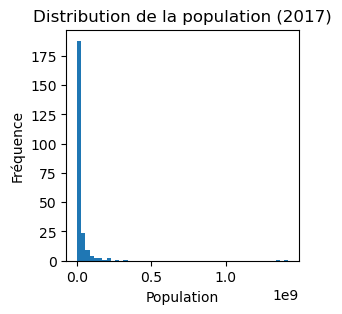

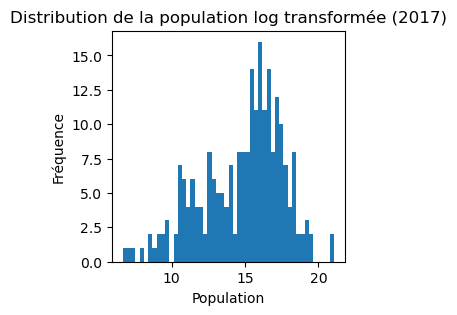

In [65]:
# Affichage la taille de la population
plt.subplots(figsize=(3,3))
plt.hist(df_pop_2017["population"], bins=50)
plt.title("Distribution de la population (2017)")
plt.xlabel("Population")
plt.ylabel("Fréquence")
plt.show()

plt.subplots(figsize=(3,3))
plt.hist(df_pop_2017["log_population"], bins=50)
plt.title("Distribution de la population log transformée (2017)")
plt.xlabel("Population")
plt.ylabel("Fréquence")
plt.show()


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.2 - Analyse du fichier disponibilite (df_dist), variables: Consumation, DIR (nourriture, importations) </h3>
</div>

In [72]:
# Afficher des 5 premières lignes du dataset
df_disp.head()

,Code Domaine,Domaine,Code zone,Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole
0,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5511,Production,2511,Blé et produits,2017,2017,Milliers de tonnes,4281.0,S,Données standardisées
1,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5611,Importations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,2302.0,S,Données standardisées
2,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5072,Variation de stock,2511,Blé et produits,2017,2017,Milliers de tonnes,-119.0,S,Données standardisées
3,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5911,Exportations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,0.0,S,Données standardisées
4,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5301,Disponibilité intérieure,2511,Blé et produits,2017,2017,Milliers de tonnes,6701.0,S,Données standardisées


In [73]:
# information générale sur ce dataset
print("Nombre des observations:",df_disp.shape[0])
print("Nombre des variables:",df_disp.shape[1])
print()
print("Nombre des lignes dupliquées:",df_disp.duplicated().sum())
print()
print("Dèja, un peut constate que il n'y a pas de NaN (voir ci-dessous) et pas des lignes doublons (voir ci-dessus) dans ce dataset:")
print()
df_disp.info()

Nombre des observations: 176600
Nombre des variables: 14

Nombre des lignes dupliquées: 0

Dèja, un peut constate que il n'y a pas de NaN (voir ci-dessous) et pas des lignes doublons (voir ci-dessus) dans ce dataset:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 176600 entries, 0 to 176599
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Code Domaine            176600 non-null  object 
 1   Domaine                 176600 non-null  object 
 2   Code zone               176600 non-null  int64  
 3   Zone                    176600 non-null  object 
 4   Code Élément            176600 non-null  int64  
 5   Élément                 176600 non-null  object 
 6   Code Produit            176600 non-null  int64  
 7   Produit                 176600 non-null  object 
 8   Code année              176600 non-null  int64  
 9   Année                   176600 non-null  int64  
 10  Unité             

In [74]:
# Créer une nouvelle colonne avec un nom de pays normalisé
df_disp.insert(loc = 0,
          column = "pays_norm",
          value = df_disp["Zone"].apply(normalize))

In [75]:
# Sélectionner les observations d'intérêt
df_disp["Année"].unique() # verification l'année 2017

df_disp_volailles = df_disp[df_disp["Produit"].str.contains("Volailles")] # selectioner les lignes qui contiennent "Volailles"
df_disp_volailles["Produit"].unique()

print("Calcul de contrôle, somme de 'Valeurs':",df_disp_volailles["Valeur"].sum()) # calcul de contrôle pour vérifier si toutes les valeurs sont présentes (répété ci-dessous après le tableau croisé dynamique)
df_disp["Zone"].nunique() # verification l'année 2017
df_disp.head()


Calcul de contrôle, somme de 'Valeurs': 409345.09


,pays_norm,Code Domaine,Domaine,Code zone,Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole
0,afghanistan,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5511,Production,2511,Blé et produits,2017,2017,Milliers de tonnes,4281.0,S,Données standardisées
1,afghanistan,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5611,Importations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,2302.0,S,Données standardisées
2,afghanistan,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5072,Variation de stock,2511,Blé et produits,2017,2017,Milliers de tonnes,-119.0,S,Données standardisées
3,afghanistan,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5911,Exportations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,0.0,S,Données standardisées
4,afghanistan,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5301,Disponibilité intérieure,2511,Blé et produits,2017,2017,Milliers de tonnes,6701.0,S,Données standardisées


In [76]:
# Créer une pivot table pour avoir la disponibilité alimentaire de volailles par pays en 2017
df_disp_volailles_pivot = df_disp_volailles.pivot_table(index=["pays_norm","Code zone","Zone"], columns="Élément", values="Valeur").reset_index()
df_disp_volailles_pivot.fillna(0, inplace=True)
print("Calcul de contrôle, somme de 'Valeurs':",df_disp_volailles_pivot.iloc[:,3:20].sum().sum()) # calcul de contrôle, la valeur doit correspondre au calcul de contrôle ci-dessus

# Multiplie les variables en "Milliers de tonnes" avec 1000 pour optenir des valeurs en tonnes.... DO THIS LATER, IF NEEDED!!
df_disp_volailles_pivot.head()


Calcul de contrôle, somme de 'Valeurs': 409345.08999999997


Élément,pays_norm,Code zone,Zone,Alimentation pour touristes,Aliments pour animaux,Autres utilisations (non alimentaire),Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Résidus,Semences,Traitement,Variation de stock
0,afghanistan,2,Afghanistan,0.0,0.0,0.0,5.0,1.53,0.33,0.54,57.0,0.0,29.0,55.0,2.0,28.0,0.0,0.0,0.0,0.0
1,afrique du sud,202,Afrique du Sud,0.0,0.0,0.0,143.0,35.69,9.25,14.11,2118.0,63.0,514.0,2035.0,83.0,1667.0,0.0,0.0,0.0,0.0
2,albanie,3,Albanie,0.0,0.0,0.0,85.0,16.36,6.45,6.26,47.0,0.0,38.0,47.0,0.0,13.0,0.0,0.0,0.0,4.0
3,algerie,4,Algérie,0.0,0.0,0.0,22.0,6.38,1.50,1.97,277.0,0.0,2.0,264.0,13.0,275.0,0.0,0.0,0.0,0.0
4,allemagne,79,Allemagne,0.0,0.0,0.0,71.0,19.47,4.16,7.96,1739.0,646.0,842.0,1609.0,0.0,1514.0,-38.0,0.0,167.0,-29.0


In [78]:
# Calculation le ratio de dépendance d'importation pour les volailles

# Deux calcules possibles pour la dépendance d'importation:
# Dépendance d'importatio = (Importations - Exportations) / Consommation alimentaire
# Dépendance d'importatio = (Nourriture - Production) / Nourriture
# (Nourriture = Consommation alimentaire) 

df_disp_volailles_pivot["Dependance_importation_ratio"] = (df_disp_volailles_pivot["Importations - Quantité"] - df_disp_volailles_pivot["Exportations - Quantité"]) / df_disp_volailles_pivot["Nourriture"] 
# df_disp_volailles_pivot["Dependance_importation_ratio2"] = (df_disp_volailles_pivot["Nourriture"] - df_disp_volailles_pivot["Production"]) / df_disp_volailles_pivot["Nourriture"]   

# calcules des controle
# df_disp_volailles_pivot["Disponibilite_interieure_calcule"] = df_disp_volailles_pivot["Production"] + df_disp_volailles_pivot["Importations - Quantité"] - df_disp_volailles_pivot["Exportations - Quantité"] - df_disp_volailles_pivot["Variation de stock"]
# df_disp_volailles_pivot["Consommation_alimentaire_calcule"] = df_disp_volailles_pivot["Disponibilite_interieure_calcule"] - df_disp_volailles_pivot["Pertes"] - df_disp_volailles_pivot["Résidus"] - df_disp_volailles_pivot["Semences"] - df_disp_volailles_pivot["Traitement"] - df_disp_volailles_pivot["Alimentation pour touristes"] - df_disp_volailles_pivot["Aliments pour animaux"] - df_disp_volailles_pivot["Autres utilisations (non alimentaire)"]
# df_disp_volailles_pivot["Dependance_importation_ratio3"] = (df_disp_volailles_pivot["Importations - Quantité"] - df_disp_volailles_pivot["Exportations - Quantité"]) / df_disp_volailles_pivot["Consommation_alimentaire_calcule"] 
# df_disp_volailles_pivot["Dependance_importation_2"] = (df_disp_volailles_pivot["Consommation_alimentaire_calcule"] - df_disp_volailles_pivot["Production"]) / df_disp_volailles_pivot["Consommation_alimentaire_calcule"]   


In [79]:
# Reduir le dataset pour les colonnes d'intérêt
df_disp_calc_2017 = df_disp_volailles_pivot.loc[:,["pays_norm","Zone","Nourriture","Disponibilité alimentaire en quantité (kg/personne/an)","Dependance_importation_ratio","Importations - Quantité","Exportations - Quantité"]]
df_disp_calc_2017.rename(columns={"Zone":"pays","Nourriture":"norriture","Disponibilité alimentaire en quantité (kg/personne/an)":"consumations","Dependance_importation_ratio":"DIR","Importations - Quantité":"importations","Exportations - Quantité":"exportations"}, inplace=True)

print("Nombre des observations:",df_disp_calc_2017.shape[0])
print("Nombre des pays unique:",df_disp_calc_2017["pays"].nunique())
print("Nombre des variables:",df_disp_calc_2017.shape[1])
df_pop_2017.head(5)
df_disp_calc_2017.head()


Nombre des observations: 172
Nombre des pays unique: 172
Nombre des variables: 7


Élément,pays_norm,pays,norriture,consumations,DIR,importations,exportations
0,afghanistan,Afghanistan,55.0,1.53,0.527273,29.0,0.0
1,afrique du sud,Afrique du Sud,2035.0,35.69,0.221622,514.0,63.0
2,albanie,Albanie,47.0,16.36,0.808511,38.0,0.0
3,algerie,Algérie,264.0,6.38,0.007576,2.0,0.0
4,allemagne,Allemagne,1609.0,19.47,0.121815,842.0,646.0


In [80]:
# Ajouter le code pays ISO 3 à l'ensemble de données, en utilisant le nom de pays normalisé:
df_clean, unmatch = match_countries_to_iso3(df_disp_calc_2017, "pays_norm", threshold=80)

In [81]:
# Rechercher les erreurs
print(unmatch) # unmatch
df_clean[df_clean["iso3"].duplicated(False)] # duplicats de iso3

       pays_norm
85  kirghizistan


,pays_norm,pays,norriture,consumations,DIR,importations,exportations,country_matched,iso3,country_fr,country_norm_fr
31,chine - ras de hong-kong,Chine - RAS de Hong-Kong,391.0,53.51,0.624041,907.0,663.0,chine,CHN,Chine,chine
32,chine - ras de macao,Chine - RAS de Macao,21.0,34.47,1.095238,23.0,0.0,chine,CHN,Chine,chine
33,"chine, continentale","Chine, continentale",17518.0,12.33,-0.007078,452.0,576.0,chine,CHN,Chine,chine
34,"chine, taiwan province de","Chine, Taiwan Province de",785.0,33.17,0.194904,161.0,8.0,chine,CHN,Chine,chine
132,republique democratique populaire lao,République démocratique populaire lao,0.0,10.91,NaN,0.0,0.0,republique democratique populaire lao,LAO,République démocratique populaire lao,republique democratique populaire lao
134,republique populaire democratique de coree,République populaire démocratique de Corée,41.0,1.62,0.000000,0.0,0.0,republique democratique populaire lao,LAO,République démocratique populaire lao,republique democratique populaire lao


In [82]:
# Corrections de l'ISO3 dans l'ensemble de données df_pop_2017
# unmatch
df_clean.loc[(df_clean["pays"] == "Kirghizistan"),"iso3"] = "KGZ"

# match incorrecte
df_clean.loc[(df_clean["pays"] == "Chine - RAS de Hong-Kong"),"iso3"] = "HKG"
df_clean.loc[(df_clean["pays"] == "Chine - RAS de Macao"),"iso3"] = "MAC"
df_clean.loc[(df_clean["pays"] == "Chine, Taiwan Province de"),"iso3"] = "TWN"
df_clean.loc[(df_clean["pays"] == "République populaire démocratique de Corée"),"iso3"] = "PRK"

df_clean.loc[(df_clean["pays"] == "Congo"),"iso3"] = "COG"    # wrongly coded                                ### ADDED without trial... check that it works!

df_disp_calc_2017 = df_clean

In [83]:
# Vérifier qu'il n'y a pas de doublons dans l'iso3
df_disp_calc_2017[df_disp_calc_2017["iso3"].duplicated(False)]

,pays_norm,pays,norriture,consumations,DIR,importations,exportations,country_matched,iso3,country_fr,country_norm_fr


In [84]:
# Ne conservez que les variables pertinentes
df_disp_calc_2017 = df_disp_calc_2017.drop(columns=["pays_norm","pays","country_fr","country_norm_fr","country_matched"])

print("Control:")
print("Nombre des observations:",df_disp_calc_2017.shape[0])
print("Nombre des pays unique:",df_disp_calc_2017["iso3"].nunique())
df_disp_calc_2017.head(3)

Control:
Nombre des observations: 172
Nombre des pays unique: 172


,norriture,consumations,DIR,importations,exportations,iso3
0,55.0,1.53,0.527273,29.0,0.0,AFG
1,2035.0,35.69,0.221622,514.0,63.0,ZAF
2,47.0,16.36,0.808511,38.0,0.0,ALB


Il y a 26 pays sont de grands exportateurs de poulet
Il y a 17 pays sont autosuffisants en poulet
Il y a 127 pays dépendent des importations de poulet


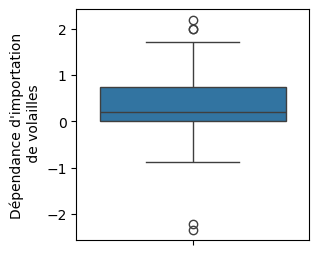

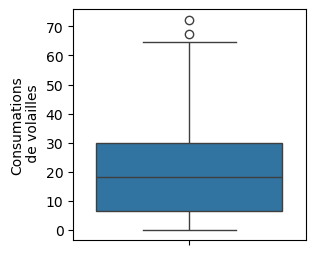

In [87]:
# Affichage des statistiques descriptives de la variable DIR Dependence Importation reatio              ### CORRECTUIN!!
print(f"Il y a {(df_disp_calc_2017["DIR"] < 0).sum() } pays sont de grands exportateurs de poulet") 
print(f"Il y a {(df_disp_calc_2017["DIR"] == 0).sum() } pays sont autosuffisants en poulet") 
print(f"Il y a {(df_disp_calc_2017["DIR"] > 0).sum() } pays dépendent des importations de poulet") 

plt.subplots(figsize=(3,3))
sns.boxplot(df_disp_calc_2017["DIR"])
plt.ylabel("Dépendance d'importation\n de volailles")
plt.show()

plt.subplots(figsize=(3,3))
sns.boxplot(df_disp_calc_2017["consumations"])
plt.ylabel("Consumations\n de volailles")
plt.show()


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.3 - Analyse du fichier disponibilite 2010 à 2017 (df_dist_2010_17), variable: consumption_trend </h3>
</div>

In [88]:
# Afficher des 5 premières lignes du dataset
df_disp_2010_17.head(3)


,Code zone,Code zone (M49),Zone,Code Produit,Code Produit (FBS),Produit,Code aliment,Aliment,Unite,Y2010,...,Y2014,Y2015,Y2016,Y2017,Y2018,Y2019,Y2020,Y2021,Y2022,Y2023
0,2,'004,Afghanistan,2501,'S2501,Population,511,Population totale,1000 No,28284.09,...,32792.52,33831.76,34700.61,35688.93,36743.04,37856.12,39068.98,40000.41,40578.84,41454.76
1,2,'004,Afghanistan,2901,'S2901,Total General,664,Disponibilité alimentaire (Kcal/personne/jour),kcal/personne/jour,2200.21,...,2270.45,2251.27,2240.71,2307.21,2261.79,2223.10,2259.95,2244.73,2268.63,2314.63
2,2,'004,Afghanistan,2901,'S2901,Total General,661,Disponibilité alimentaire (Kcal),millions de kcal,22714261.33,...,27175651.99,27799992.36,28380157.97,30054816.91,30333352.71,30717599.09,32227343.15,32773345.26,33601287.96,35022662.41


In [89]:
# Créer une nouvelle colonne avec un nom de pays normalisé
df_disp_2010_17.insert(loc = 0,
          column = "pays_norm",
          value = df_disp_2010_17["Zone"].apply(normalize))


In [90]:
# Sélectionner les observations d'intérêt
# Sélectionnez les observations concernant les produits de volaille
df_disp_cont_volailles = df_disp_2010_17[df_disp_2010_17["Produit"].str.contains("Volailles")] 
print("Contrôle, contient le noveau dataset uniquement des produits de volaille? :",df_disp_cont_volailles["Produit"].unique())

# Sélectionnez les observations concernant consommations (kg/personne/an)
df_disp_cont_volailles_consump = df_disp_cont_volailles[df_disp_cont_volailles["Aliment"].str.contains("kg/personne/an")]  
print("Contrôle, contient le noveau dataset uniquement la consommation en (kg/personne/an)? :",df_disp_cont_volailles_consump["Aliment"].unique())

# Vérifier la présence de valeurs NaN - et les supprimer 
mask = df_disp_cont_volailles_consump["Y2010"].isna()
df_disp_cont_volailles_consump = df_disp_cont_volailles_consump[~mask] # Exclure les lignes contenant des valeurs NaN

# Supprimer les années postérieures à 2017
df_disp_cont_volailles_consump = df_disp_cont_volailles_consump.drop(columns=["Code zone (M49)","Code Produit","Code Produit (FBS)","Y2018","Y2019","Y2020","Y2021","Y2022","Y2023"]) 

df_disp_cont_volailles_consump.reset_index(inplace=True)

Contrôle, contient le noveau dataset uniquement des produits de volaille? : ['Viande de Volailles']
Contrôle, contient le noveau dataset uniquement la consommation en (kg/personne/an)? : ['Disponibilité alimentaire en quantité (kg/personne/an)']


In [91]:
# Ajustez une régression linéaire aux valeurs de consommation entre 2010 et 2017 et enregistrez le coefficient de pente - un indicateur de la tendance de la consommation de volaille
x = np.array([2010,2011,2012,2013,2014,2015,2016,2017])
reg_line = []

for i in range(0,(df_disp_cont_volailles_consump.shape[0])):
    
    y = (df_disp_cont_volailles_consump.loc[i,["Y2010","Y2011","Y2012","Y2013","Y2014","Y2015","Y2016","Y2017"]]).astype(float)
    x_centered = x - x.mean()  # Centrer les années pour stabiliser l'intercept de la régression et faciliter l'interprétation du coefficient de pente

    coef = np.polyfit(x_centered,y,1)
    poly1d_fn = np.poly1d(coef) 
    reg_line.append(coef[0])
    # print(df_disp_cont_volailles_consump.loc[i,"Zone"], coef[0])

df_cons_trend = (
    df_disp_cont_volailles_consump
    .assign(consumption_trend=reg_line)
    .loc[:, ["pays_norm","Zone", "consumption_trend"]]
    .rename(columns={"Zone": "pays"})
)
df_cons_trend

,pays_norm,pays,consumption_trend
0,afghanistan,Afghanistan,-0.038929
1,afrique du sud,Afrique du Sud,0.532500
2,albanie,Albanie,-0.399762
3,algerie,Algérie,-0.015833
4,allemagne,Allemagne,-0.029048
...,...,...,...
200,pays les moins developpes,Pays les moins développés,0.099524
201,pays sans littoral en voie de developpement,Pays sans littoral en voie de développement,0.073810
202,petites iles en voie de developpement,Petites îles en voie de Développement,0.677976
203,pays a faible revenu et a deficit vivrier,Pays à faible revenu et à déficit vivrier,0.022857


In [92]:
# Ajouter le code pays ISO 3 à l'ensemble de données, en utilisant le nom de pays normalisé:
df_clean, unmatch = match_countries_to_iso3(df_cons_trend, "pays_norm", threshold=80)


In [93]:
# Vérifiez les pays correspondants
pd.set_option('display.max_rows', None) # afficher toutes les lignes
# df_clean.loc[:,["pays_norm","pays","country_norm_fr","country_matched","country_fr","iso3"]]
print(set(df_clean["pays_norm"]) - set(df_clean["country_norm_fr"]))
print(set(df_clean["country_norm_fr"]) - set(df_clean["pays_norm"]))
 

{'pays sans littoral en voie de developpement', 'tchequie', 'pays a faible revenu et a deficit vivrier', 'amerique du sud', 'afrique centrale', 'melanesie', 'afrique', 'petites iles en voie de developpement', 'asie meridionale', 'amerique centrale', 'pays les moins developpes', 'venezuela (republique bolivarienne du)', 'turkiye', 'union europeenne (27)', 'asie du sud-est', 'micronesie', 'europe orientale', "iran (republique islamique d')", 'asie centrale', 'republique de coree', 'europe septentrionale', 'republique de moldova', 'republique populaire democratique de coree', 'chine - ras de macao', 'asie orientale', 'europe', "royaume-uni de grande-bretagne et d'irlande du nord", 'egypte', 'pays-bas (royaume des)', 'europe occidentale', 'afrique australe', 'afrique orientale', 'republique-unie de tanzanie', 'chine, taiwan province de', 'republique democratique du congo', 'cabo verde', 'polynesie', 'ameriques', 'asie occidentale', 'amerique septentrionale', 'congo', 'oceanie', "etats-unis

In [94]:
# Reset - afficher toutes les lignes
pd.reset_option('display.max_rows')


In [95]:
# Corrections de l'ISO3 dans l'ensemble de données df_pop_2017
# unmatch
df_clean.loc[(df_clean["pays"] == "Kirghizistan"),"iso3"] = "KGZ"
df_clean.loc[(df_clean["pays"] == "Türkiye"),"iso3"] = "TUR"
df_clean.loc[(df_clean["pays"] == "Océanie"),"iso3"] = "BIG"        # Ce n'est pas un pays, donc sans intérêt pour l'ensemble de données final.
df_clean.loc[(df_clean["pays"] == "Mélanésie"),"iso3"] = "BIG"      # Ce n'est pas un pays, donc sans intérêt pour l'ensemble de données final.
df_clean.loc[(df_clean["pays"] == "Imp Nets Prod Alim Dvpm"),"iso3"] = "BIG"      # Ce n'est pas un pays, donc sans intérêt pour l'ensemble de données final.

# match incorrecte
df_clean.loc[(df_clean["pays"] == "Chine - RAS de Hong-Kong"),"iso3"] = "HKG"
df_clean.loc[(df_clean["pays"] == "Chine - RAS de Macao"),"iso3"] = "MAC"
df_clean.loc[(df_clean["pays"] == "Chine, Taiwan Province de"),"iso3"] = "TWN"
df_clean.loc[(df_clean["pays"] == "République populaire démocratique de Corée"),"iso3"] = "PRK"
#df_clean.loc[(df_clean["pays"] == "Chine - RAS de Hong-Kong"),"iso3"] = "HKG"
df_clean.loc[(df_clean["pays"] == "Australie et Nouvelle-Zélande"),"iso3"] = "BIG" # Ce n'est pas un pays, donc sans intérêt pour l'ensemble de données final.


# dupliqué, en raison d'une match incorrecte
df_clean.loc[(df_clean["pays"] == "Congo"),"iso3"] = "COG"    # wrongly coded

# dupliqué
df_clean.loc[(df_clean["pays"] == "Amérique du Sud"),"iso3"] = "BIG"            # Ce n'est pas un pays, donc sans intérêt pour l'ensemble de données final
df_clean.loc[(df_clean["pays"] == "Chine"),"iso3"] = "CHN_ALL"                  # La Chine continentale a été utilisée dans les datasets précédents
df_clean.loc[(df_clean["pays"] == "Amérique du Sud"),"iso3"] = "BIG"            # Ce n'est pas un pays, donc sans intérêt pour l'ensemble de données final
df_clean.loc[(df_clean["pays"] == "Polynésie"),"iso3"] = "BIG"                  # Ce n'est pas un pays, donc sans intérêt pour l'ensemble de données final
df_clean.loc[(df_clean["pays"] == "Asie du Sud-Est"),"iso3"] = "BIG"            # Ce n'est pas un pays, donc sans intérêt pour l'ensemble de données final

df_cons_trend = df_clean

In [96]:
df_clean[df_clean["pays_norm"].str.contains("guy")]
#df_merge1[df_merge1["iso3"].duplicated(False)]


,pays_norm,pays,consumption_trend,country_matched,iso3,country_fr,country_norm_fr
67,guyana,Guyana,1.327619,guyana,GUY,Guyana,guyana


In [97]:
# Vérifier qu'il n'y a pas de doublons dans l'iso3
print("Il existe encore des doublons, mais il s'agit de régions plus vastes et non de pays individuels...")
print()
df_cons_trend[df_cons_trend["iso3"].duplicated(False)].head()

Il existe encore des doublons, mais il s'agit de régions plus vastes et non de pays individuels...



,pays_norm,pays,consumption_trend,country_matched,iso3,country_fr,country_norm_fr
172,afrique,Afrique,0.053452,"moyen-orient, afrique du nord, afghanistan et ...",MEA,"Moyen-Orient, Afrique du Nord, Afghanistan et ...","moyen-orient, afrique du nord, afghanistan et ..."
173,afrique orientale,Afrique orientale,0.053810,"moyen-orient, afrique du nord, afghanistan et ...",MEA,"Moyen-Orient, Afrique du Nord, Afghanistan et ...","moyen-orient, afrique du nord, afghanistan et ..."
174,afrique centrale,Afrique centrale,0.003571,europe centrale et les pays baltes\r\n,CEB,Europe centrale et les pays baltes\r\n,europe centrale et les pays baltes\r\n
175,afrique septentrionale,Afrique septentrionale,0.025119,"moyen-orient, afrique du nord, afghanistan et ...",MEA,"Moyen-Orient, Afrique du Nord, Afghanistan et ...","moyen-orient, afrique du nord, afghanistan et ..."
176,afrique australe,Afrique australe,0.463929,"moyen-orient, afrique du nord, afghanistan et ...",MEA,"Moyen-Orient, Afrique du Nord, Afghanistan et ...","moyen-orient, afrique du nord, afghanistan et ..."


In [98]:
# Ne conservez que les variables pertinentes
df_cons_trend = df_cons_trend.drop(columns=["pays_norm","pays","country_fr","country_norm_fr","country_matched"])
df_cons_trend


,consumption_trend,iso3
0,-0.038929,AFG
1,0.532500,ZAF
2,-0.399762,ALB
3,-0.015833,DZA
4,-0.029048,DEU
...,...,...
200,0.099524,FCS
201,0.073810,EAS
202,0.677976,CHI
203,0.022857,LIC


Il y a 45 pays qui, en moyenne, ont diminué leur consommation de volaille
Il y a 160 pays qui, en moyenne, ont augmenté leur consommation de volaille
L'ensemble de données comprend 185 pays (y compris des groupements de pays, qui seront exclus lors de la fusion).


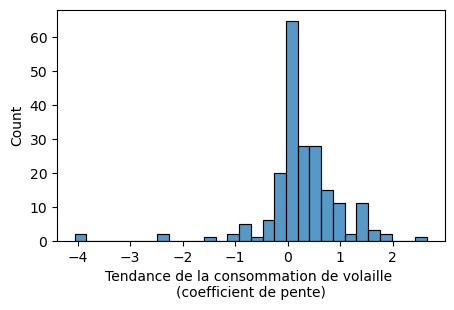

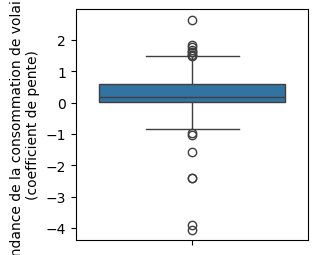

In [99]:
# Afficheage des statistiques descriptives de la variable consumption_trend
print(f"Il y a {(df_cons_trend["consumption_trend"] <= 0).sum() } pays qui, en moyenne, ont diminué leur consommation de volaille") 
print(f"Il y a {(df_cons_trend["consumption_trend"] > 0).sum() } pays qui, en moyenne, ont augmenté leur consommation de volaille") 
print(f"L'ensemble de données comprend {df_cons_trend['iso3'].nunique()} pays (y compris des groupements de pays, qui seront exclus lors de la fusion).")

plt.subplots(figsize=(5,3))
sns.histplot(df_cons_trend["consumption_trend"], bins=30)
plt.xlabel("Tendance de la consommation de volaille \n(coefficient de pente)")
plt.show()

plt.subplots(figsize=(3,3))
sns.boxplot(df_cons_trend["consumption_trend"])
plt.ylabel("Tendance de la consommation de volaille \n(coefficient de pente)")
plt.show()

In [100]:
# Ajoutez une ligne avec une estimation d'imputation pour le Japon, qui est un pays important pour l'analyse et qui manque dans l'ensemble de données final
df_cons_trend = pd.concat([df_cons_trend, pd.DataFrame([{"iso3": "JPN", "consumption_trend": df_cons_trend["consumption_trend"].mean()}])], ignore_index=True)
df_cons_trend

,consumption_trend,iso3
0,-0.038929,AFG
1,0.532500,ZAF
2,-0.399762,ALB
3,-0.015833,DZA
4,-0.029048,DEU
...,...,...
201,0.073810,EAS
202,0.677976,CHI
203,0.022857,LIC
204,0.096190,BIG


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.4 - Analyse du fichier GNI per capita (df_GNI), variables: GNI </h3>
</div>

In [102]:
# Afficher des 5 premières lignes du dataset
df_GNI.head()

,country_code,country,GNI_per_capita,year
0,ZH,Afrique orientale et méridionale,1370.752264,2017
1,ZI,Afrique occidentale et centrale,1584.341856,2017
2,1A,Le monde arabe,6048.461307,2017
3,S3,Petits états des Caraïbes,12922.971444,2017
4,B8,Europe centrale et les pays baltes,13154.496267,2017


In [103]:
# information générale sur ce dataset
print("Nombre des observations:",df_GNI.shape[0])
print("Nombre des variables:",df_GNI.shape[1])
print()
print("Nombre des lignes dupliquées:",df_GNI.duplicated().sum())
print()
print("Dèja, un peut constate que il n'y a pas des lignes doublons (voir ci-dessus), mais 15 NaN (voir ci-dessous) dans ce dataset:")
print()
df_GNI.info()

Nombre des observations: 266
Nombre des variables: 4

Nombre des lignes dupliquées: 0

Dèja, un peut constate que il n'y a pas des lignes doublons (voir ci-dessus), mais 15 NaN (voir ci-dessous) dans ce dataset:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   country_code    266 non-null    object 
 1   country         266 non-null    object 
 2   GNI_per_capita  249 non-null    float64
 3   year            266 non-null    object 
dtypes: float64(1), object(3)
memory usage: 8.4+ KB


In [104]:
# Créer une nouvelle colonne avec un nom de pays normalisé
df_GNI.insert(loc = 0,
          column = "pays_norm",
          value = df_GNI["country"].apply(normalize))

In [105]:
# Exclure les observations avec NaN
print("Les pays exclus (GNI manquant) \n",df_GNI.loc[df_GNI["GNI_per_capita"].isna(),"country"])
print()
df_GNI = df_GNI.dropna(subset=["GNI_per_capita"])
print("Après exclusion des observations avec NaN dans la variable GNI_per_capita:")
print()
df_GNI.info()

Les pays exclus (GNI manquant) 
 35                         Non classifié
52                     Samoa américaines
53                               Andorre
76             Îles Vierges britanniques
88                  Îles Anglo-Normandes
110                             Érythrée
124                            Gibraltar
126                            Groenland
128                                 Guam
152    Corée, République démocratique de
163                        Liechtenstein
179                               Monaco
189                   Nouvelle-Calédonie
195                            Mariannes
227                        Soudan du Sud
232                    Saint-Martin (fr)
261                    Îles Vierges (EU)
Name: country, dtype: object

Après exclusion des observations avec NaN dans la variable GNI_per_capita:

<class 'pandas.core.frame.DataFrame'>
Index: 249 entries, 0 to 265
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------         

In [106]:
# Reduir le dataset pour les colonnes d'intérêt (Zone et Valeur de population)
df_GNI["year"].unique()
df_GNI = df_GNI.loc[:,["pays_norm","country","GNI_per_capita"]]
df_GNI.rename(columns={"country_code":"code_pays","country":"pays"},inplace=True)

print("Nombre des observations:",df_GNI.shape[0])
print("Nombre des pays unique:",df_GNI["pays"].nunique())
print("Nombre des variables:",df_GNI.shape[1])
df_GNI.head(5)


Nombre des observations: 249
Nombre des pays unique: 249
Nombre des variables: 3


,pays_norm,pays,GNI_per_capita
0,afrique orientale et meridionale,Afrique orientale et méridionale,1370.752264
1,afrique occidentale et centrale,Afrique occidentale et centrale,1584.341856
2,le monde arabe,Le monde arabe,6048.461307
3,petits etats des caraibes,Petits états des Caraïbes,12922.971444
4,europe centrale et les pays baltes,Europe centrale et les pays baltes,13154.496267


In [107]:
# Ajouter le code pays ISO 3 à l'ensemble de données, en utilisant le nom de pays normalisé:
df_clean, unmatch = match_countries_to_iso3(df_GNI, "pays_norm", threshold=80)

In [108]:
# Rechercher les erreurs
print(unmatch) # unmatch
print()
print("Il existe des doublons, mais il s'agit de régions plus vastes et non de pays individuels... ")
print()
df_clean[df_clean["iso3"].duplicated(False)] # duplicats de iso3


Empty DataFrame
Columns: [pays_norm]
Index: []

Il existe des doublons, mais il s'agit de régions plus vastes et non de pays individuels... 



,pays_norm,pays,GNI_per_capita,country_matched,iso3,country_fr,country_norm_fr
0,afrique orientale et meridionale,Afrique orientale et méridionale,1370.752264,bird et ida,IBT,BIRD et IDA,bird et ida
1,afrique occidentale et centrale,Afrique occidentale et centrale,1584.341856,fragile et les situations de conflit touchees\r\n,FCS,Fragile et les situations de conflit touchées\r\n,fragile et les situations de conflit touchees\r\n
14,fragile et les situations de conflit touchees,Fragile et les situations de conflit touchées,1483.057073,fragile et les situations de conflit touchees\r\n,FCS,Fragile et les situations de conflit touchées\r\n,fragile et les situations de conflit touchees\r\n
18,bird et ida,BIRD et IDA,4598.238259,bird et ida,IBT,BIRD et IDA,bird et ida


In [109]:
# Vérifiez les pays correspondants
pd.set_option('display.max_rows', None) # afficher toutes les lignes
# df_clean.loc[:,["pays_norm","pays","country_norm_fr","country_matched","country_fr","iso3"]]
print(set(df_clean["pays_norm"]) - set(df_clean["country_norm_fr"]))
print(set(df_clean["country_norm_fr"]) - set(df_clean["pays_norm"]))
print()

print("Aucune correction nécessaire!")


{'afrique orientale et meridionale', 'afrique occidentale et centrale', 'fragile et les situations de conflit touchees', 'cabo verde', 'europe centrale et les pays baltes'}
{'cabo verde ', 'fragile et les situations de conflit touchees\r\n', 'europe centrale et les pays baltes\r\n'}

Aucune correction nécessaire!


In [110]:
# Reset - afficher toutes les lignes
pd.reset_option('display.max_rows')

In [111]:
# Modifier le nom de le dataset et ne conservez que les variables pertinentes
df_GNI = df_clean

df_GNI = df_GNI.drop(columns=["pays_norm","pays","country_fr","country_norm_fr","country_matched"])
df_GNI.head(3)


,GNI_per_capita,iso3
0,1370.752264,IBT
1,1584.341856,FCS
2,6048.461307,ARB


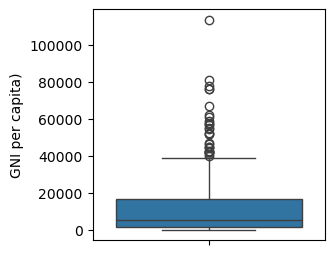

In [112]:
# Afficheage des statistiques descriptives de la variable GNI per capita
plt.subplots(figsize=(3,3))
sns.boxplot(df_GNI["GNI_per_capita"])
plt.ylabel("GNI per capita)")
plt.show()

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.5 - Analyse du fichier Geolocalisation des pays (df_geo), variable: distance_km</h3>
</div>

In [113]:
# Afficher des 5 premières lignes du dataset
df_geo.head()

,iso2,iso3,cnum,country,pays,area,dis_int,landlocked,continent,city_en,...,lang9_2,lang9_3,lang9_4,colonizer1,colonizer2,colonizer3,colonizer4,short_colonizer1,short_colonizer2,short_colonizer3
0,AW,ABW,533,Aruba,Aruba,193,5.225315,0,America,Oranjestad,...,.,.,.,NLD,.,.,.,.,.,.
1,AF,AFG,4,Afghanistan,Afghanistan,652225,303.761400,1,Asia,Kabul,...,Uzbek,.,.,.,.,.,.,GBR,.,.
2,AO,AGO,24,Angola,Angola,1246700,419.966600,0,Africa,Luanda,...,.,.,.,PRT,.,.,.,.,.,.
3,AI,AIA,660,Anguilla,Anguilla,102,3.798690,0,America,The Valley,...,.,.,.,GBR,.,.,.,.,.,.
4,AL,ALB,8,Albania,Albanie,28748,63.773110,0,Europe,Tirana,...,.,.,.,TUR,.,.,.,.,.,.


In [114]:
# Calculez la distance (great circle distance, en km) entre Paris et la capitale* de chaque pays
# * Pour les grands pays, on utilise la distance jusqu'à la deuxième plus grande ville si sa distance à Paris est plus courte que celle jusqu'à la capitale.

# Coordinates de Paris
mask = df_geo["city_fr"] == "Paris"
df_geo.loc[mask,["lat","lon"]] 
paris = (48.86666, 2.333333)

# Dataset avec position des capitales
data = df_geo[["iso3","pays","city_fr","lat","lon"]].drop_duplicates()
df_dist = pd.DataFrame(data)

# Calculez la distance de Paris
df_dist["distance_km"] = df_dist.apply(
    lambda row: geodesic(paris, (row["lat"], row["lon"])).km,
    axis=1
)
df_dist.drop(columns=["lat","lon"], inplace=True)
df_dist.head()

,iso3,pays,city_fr,distance_km
0,ABW,Aruba,Oranjestad,7683.645295
1,AFG,Afghanistan,Kaboul,5597.877813
2,AGO,Angola,Luanda,6480.512694
3,AIA,Anguilla,The Valley,6710.583021
4,ALB,Albanie,Tirana,1605.053520


In [115]:
# Certains grands pays ont deux villes – conservez celle qui est la plus proche de Paris
df_dist = df_dist.loc[df_dist.groupby("iso3")["distance_km"].idxmin()].reset_index(drop=True)

In [116]:
# Vérifier les doublons dans l'ISO3
df_dist[df_dist["iso3"].duplicated(False)]


,iso3,pays,city_fr,distance_km


In [117]:
# Modifier le nom de le dataset et ne conservez que les variables pertinentes
df_dist = df_dist.drop(columns=["pays","city_fr"])
print("Control:")
print("Nombre des observations:",df_dist.shape[0])
print("Nombre des pays unique:",df_dist["iso3"].nunique())
df_dist.head(3)


Control:
Nombre des observations: 225
Nombre des pays unique: 225


,iso3,distance_km
0,ABW,7683.645295
1,AFG,5597.877813
2,AGO,6480.512694


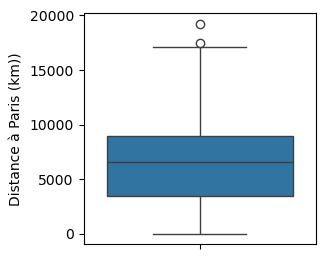

In [118]:
# Afficheage des statistiques descriptives de la variable distance à Paris
plt.subplots(figsize=(3,3))
sns.boxplot(df_dist["distance_km"])
plt.ylabel("Distance à Paris (km))")
plt.show()

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.6 - Analyse du fichier Logistic Performance Index (df_LPI), variable: LPI </h3>
</div>

In [119]:
# Afficher des 3 premières lignes du dataset
df_LPI.head(3)


,Country Name,Country Code,Indicator Name,Indicator Code,2007,2010,2012,2014,2016,2018
0,Aruba,ABW,Indice de performance logistique : performance...,LP.LPI.OVRL.XQ,NaN,NaN,NaN,NaN,NaN,NaN
1,Afrique orientale et méridionale,AFE,Indice de performance logistique : performance...,LP.LPI.OVRL.XQ,2.385238,2.38,2.464211,2.469728,2.578623,2.492222
2,Afghanistan,AFG,Indice de performance logistique : performance...,LP.LPI.OVRL.XQ,1.210000,2.24,2.300000,2.069573,2.141282,1.950000


In [120]:
# information générale sur ce dataset
print("Nombre des observations:",df_LPI.shape[0])
print("Nombre des variables:",df_LPI.shape[1])
print()
print("Nombre des lignes dupliquées:",df_LPI.duplicated().sum())
print()
print("Dèja, un peut constate que il n'y a pas des lignes doublons (voir ci-dessus), mais de 59 NaN (voir ci-dessous)!!! dans ce dataset:")
print()
print()
df_LPI.info()

Nombre des observations: 266
Nombre des variables: 10

Nombre des lignes dupliquées: 0

Dèja, un peut constate que il n'y a pas des lignes doublons (voir ci-dessus), mais de 59 NaN (voir ci-dessous)!!! dans ce dataset:


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    266 non-null    object 
 1   Country Code    266 non-null    object 
 2   Indicator Name  266 non-null    object 
 3   Indicator Code  266 non-null    object 
 4   2007            197 non-null    float64
 5   2010            202 non-null    float64
 6   2012            201 non-null    float64
 7   2014            207 non-null    float64
 8   2016            207 non-null    float64
 9   2018            207 non-null    float64
dtypes: float64(6), object(4)
memory usage: 20.9+ KB


In [121]:
# Les données de 2017 étant indisponibles, nous avons opté pour celles de 2018. 
# Il est toutefois prévisible que les conditions logistiques évoluent considérablement au cours d'une année
df_LPI_2018 = (
    df_LPI.loc[:, ["Country Name", "Country Code", "2018"]] # Le "Country Code" correspond au code ISO3
    .rename(columns={"Country Code": "iso3", "Country Name": "pays", "2018": "LPI"})
)

# Supprimer les NaN
df_LPI_2018 = df_LPI_2018.dropna()

print("Nombre des observations:",df_LPI_2018.shape[0])
print("Nombre des pays unique:",df_LPI_2018["pays"].nunique())
print("Nombre des variables:",df_LPI_2018.shape[1])
df_LPI_2018.head()

Nombre des observations: 207
Nombre des pays unique: 207
Nombre des variables: 3


,pays,iso3,LPI
1,Afrique orientale et méridionale,AFE,2.492222
2,Afghanistan,AFG,1.950000
3,Afrique occidentale et centrale,AFW,2.413333
4,Angola,AGO,2.050000
5,Albanie,ALB,2.660000


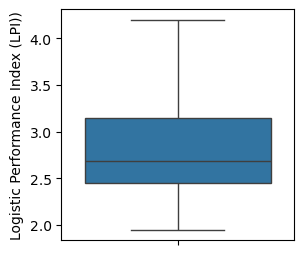

In [122]:
# Afficheage des statistiques descriptives de la variable Logistic Performance Index (LPI)
plt.subplots(figsize=(3,3))
sns.boxplot(df_LPI_2018["LPI"])
plt.ylabel("Logistic Performance Index (LPI))")
plt.show()

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.7 - Analyse du fichier Urban Population share (df_urb), variable: UPS </h3>
</div>

In [123]:
# Afficher des 3 premières lignes du dataset
df_urb.head(3)

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Aruba,ABW,Population urbaine (% du total),SP.URB.TOTL.IN.ZS,59.023670,59.072800,59.212271,59.432359,59.723340,60.075491,...,63.228837,63.007788,62.776849,62.536764,62.288276,62.002884,61.927534,61.881166,61.835149,61.790940
1,Afrique orientale et méridionale,AFE,Population urbaine (% du total),SP.URB.TOTL.IN.ZS,14.640371,14.867730,15.107367,15.353899,15.607152,15.872246,...,34.490681,34.881211,35.282987,35.714718,36.097331,36.488322,36.908543,37.360578,37.772301,38.241441
2,Afghanistan,AFG,Population urbaine (% du total),SP.URB.TOTL.IN.ZS,8.122551,8.389595,8.662664,8.942709,9.231134,9.529343,...,24.464912,24.658835,24.835282,24.999165,25.143726,25.262210,25.347862,25.393925,25.473053,25.700735


In [124]:
# information générale sur ce dataset
print("Nombre des observations:",df_urb.shape[0])
print("Nombre des variables:",df_urb.shape[1])
print()
print("Nombre des lignes dupliquées:",df_urb.duplicated().sum())
print()
print("Dèja, un peut constate que il n'y a pas des lignes doublons (voir ci-dessus), mais 1 NaN (voir ci-dessous) dans ce dataset:")
print()
print()
df_urb.info()

Nombre des observations: 266
Nombre des variables: 69

Nombre des lignes dupliquées: 0

Dèja, un peut constate que il n'y a pas des lignes doublons (voir ci-dessus), mais 1 NaN (voir ci-dessous) dans ce dataset:


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 69 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    266 non-null    object 
 1   Country Code    266 non-null    object 
 2   Indicator Name  266 non-null    object 
 3   Indicator Code  266 non-null    object 
 4   1960            265 non-null    float64
 5   1961            265 non-null    float64
 6   1962            265 non-null    float64
 7   1963            265 non-null    float64
 8   1964            265 non-null    float64
 9   1965            265 non-null    float64
 10  1966            265 non-null    float64
 11  1967            265 non-null    float64
 12  1968            265 non-null    float64
 13  1

In [125]:
# Sélectionnez les variables pertinentes et excluez les valeurs NaN  
df_urb_2017 = (
    df_urb.loc[:, ["Country Code", "2017"]] 
    .rename(columns={"Country Code": "iso3", "2017": "UPS"}) # Le "Country Code" correspond au code ISO3
)

# Supprimer les NaN
df_urb_2017 = df_urb_2017.dropna()

print("Nombre des observations:",df_urb_2017.shape[0])
print("Nombre des pays unique:",df_urb_2017["iso3"].nunique())
print("Nombre des variables:",df_urb_2017.shape[1])
df_urb_2017.head()

Nombre des observations: 265
Nombre des pays unique: 265
Nombre des variables: 2


,iso3,UPS
0,ABW,62.776849
1,AFE,35.282987
2,AFG,24.835282
3,AFW,48.747414
4,AGO,65.085053


In [126]:
# Vérifier qu'il n'y a pas de doublons dans l'iso3
df_urb_2017[df_urb_2017["iso3"].duplicated(False)]

,iso3,UPS


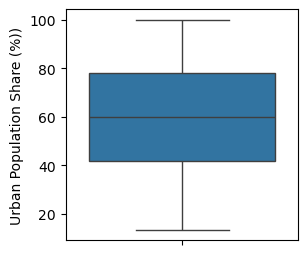

In [127]:
# Afficheage des statistiques descriptives de la variable Logistic Performance Index (LPI)
plt.subplots(figsize=(3,3))
sns.boxplot(df_urb_2017["UPS"])
plt.ylabel("Urban Population Share (%))")
plt.show()

<div style="background-color: RGB(27, 161, 226);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction du jeux des données</h2>
</div>

In [128]:
# Affichage des dimensions tous les datasets
print("df_pop_2017:",df_pop_2017.shape)
print("df_disp_calc_2017:",df_disp_calc_2017.shape)
print("df_cons_trend:",df_cons_trend.shape)
print("df_GNI:",df_GNI.shape)
print("df_dist:",df_dist.shape)
print("df_LPI_2018:",df_LPI_2018.shape)
print("df_urb_2017:",df_urb_2017.shape)

df_pop_2017: (236, 4)
df_disp_calc_2017: (172, 6)
df_cons_trend: (206, 2)
df_GNI: (249, 2)
df_dist: (225, 2)
df_LPI_2018: (207, 3)
df_urb_2017: (265, 2)


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 3.1 - Merge 1: fichiers df_pop_2017 et df_disp_calc_2017 </h3>
</div>

In [ ]:
# Fusionnez les jeux de données et examinez le nouveau dataframe                  # Calculate % population without NaN DIR!?
df_merge1 = pd.merge(df_pop_2017, df_disp_calc_2017, on=["iso3"], how="inner")
out1 = df_pop_2017[~df_pop_2017["iso3"].isin(df_disp_calc_2017["iso3"])]
out2 = df_disp_calc_2017[~df_disp_calc_2017["iso3"].isin(df_pop_2017["iso3"])]

print(f"Control: Le nouvel ensemble de données contient {df_merge1["iso3"].nunique()} pays, ce qui représente {(df_merge1.groupby(by="iso3")["population"].min().sum()/pop_total_2017 ) * 100:.0f}% de la population mondiale totale.")
print()

print("DIR (Dependence Importation Ratio ) contient 2 valeurs manquantes")
print()
df_merge1.info()


Control: Le nouvel ensemble de données contient 172 pays, ce qui représente 98% de la population mondiale totale.

DIR (Dependence Importation Ratio ) contient 2 valeurs manquantes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 172 entries, 0 to 171
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   pays_norm       172 non-null    object 
 1   population      172 non-null    float64
 2   log_population  172 non-null    float64
 3   iso3            172 non-null    object 
 4   norriture       172 non-null    float64
 5   consumations    172 non-null    float64
 6   DIR             170 non-null    float64
 7   importations    172 non-null    float64
 8   exportations    172 non-null    float64
dtypes: float64(7), object(2)
memory usage: 12.2+ KB


In [131]:
# Examiner de plus près les pays exclus de la merge
#print("Les pays exclus (non présents dans df_disp_calc_2017) \nce sont tous des pays éloignés, des îles ou des pays en développement, \net donc peu susceptibles de constituer de nouveaux marchés intéressants pour le poulet biologique. \nNous pouvons les exclure.")
print()
print(f"Les pays exclus de la 'df_pop_2017': \n {out1["pays_norm"].unique()}")
print()
print()
#print("Les pays exclus (non présents dans df_pop_2017) ce sont des régions géographiques plus vastes/continents etc, et non des pays individuels.")
print()
print(f"Les pays exclus de la 'df_disp_calc_2017': \n {out2["iso3"].unique()}")



Les pays exclus de la 'df_pop_2017': 
 ['andorre' 'anguilla' 'antilles neerlandaises (ex)' 'aruba' 'bahrein'
 'bermudes' 'bhoutan' 'bonaire, saint-eustache et saba'
 'brunei darussalam' 'burundi' 'comores' 'curacao' 'erythree' 'gibraltar'
 'groenland' 'guadeloupe' 'guam' 'guinee equatoriale' 'guyane francaise'
 'ile de man' 'iles anglo-normandes' 'iles caimanes' 'iles cook'
 'iles falkland (malvinas)' 'iles feroe' 'iles mariannes du nord'
 'iles marshall' 'iles turques-et-caiques' 'iles vierges americaines'
 'iles vierges britanniques' 'iles wallis-et-futuna' 'libye'
 'liechtenstein' 'martinique' 'mayotte' 'micronesie (etats federes de)'
 'monaco' 'montserrat' 'nauru' 'nioue' 'palaos' 'palestine'
 'papouasie-nouvelle-guinee' 'porto rico' 'qatar'
 'republique arabe syrienne' 'republique democratique du congo' 'reunion'
 'sahara occidental' 'saint-barthelemy'
 'sainte-helene, ascension et tristan da cunha' 'saint-marin'
 'saint-martin (partie francaise)' 'saint-pierre-et-miquelon'
 'sai

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 3.2 - Merge 2: fichiers df_merge1 et df_cons_trend</h3>
</div>

In [133]:
# Fusionnez les jeux de données et examinez le nouveau dataframe
df_merge2 = pd.merge(df_merge1, df_cons_trend, on=["iso3"], how="inner")
out1 = df_merge1[~df_merge1["iso3"].isin(df_cons_trend["iso3"])]
out2 = df_cons_trend[~df_cons_trend["iso3"].isin(df_merge1["iso3"])]

print(f"Control: Le nouvel ensemble de données contient {df_merge2["iso3"].nunique()} pays, ce qui représente {(df_merge2.groupby(by="iso3")["population"].min().sum()/pop_total_2017 ) * 100:.0f}% de la population mondiale totale.")
print()

print("DIR (Dependence Importation Ratio ) contient 2 valeurs manquantes")
df_merge2.info()

Control: Le nouvel ensemble de données contient 165 pays, ce qui représente 96% de la population mondiale totale.

DIR (Dependence Importation Ratio ) contient 2 valeurs manquantes
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165 entries, 0 to 164
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pays_norm          165 non-null    object 
 1   population         165 non-null    float64
 2   log_population     165 non-null    float64
 3   iso3               165 non-null    object 
 4   norriture          165 non-null    float64
 5   consumations       165 non-null    float64
 6   DIR                163 non-null    float64
 7   importations       165 non-null    float64
 8   exportations       165 non-null    float64
 9   consumption_trend  165 non-null    float64
dtypes: float64(8), object(2)
memory usage: 13.0+ KB


In [134]:
# Examiner de plus près les pays exclus de la merge
#print("Les pays exclus (non présents dans df_cons_trend) \nce sont tous des pays éloignés, ou des pays en développement, et donc peu susceptibles de constituer de nouveaux marchés intéressants pour le poulet biologique.\n Avec EXCEPTION Japon!")
print()
print(f"Les pays exclus de la df_merge1: \n {out1["pays_norm"].unique()}")
print()
print()
#print("Les pays exclus (non présents dans df_merge1) ce sont des régions géographiques plus vastes/continents etc, et non des pays individuels. ")
print()
print(f"Les pays exclus de la 'df_cons_trend': \n {out2["iso3"].unique()}")
print()
print("Faire attention, Chine Continental reste dans le dataset.")


Les pays exclus de la df_merge1: 
 ['benin' 'dominique' 'mali' 'republique centrafricaine' 'soudan' 'tchad'
 'togo']



Les pays exclus de la 'df_cons_trend': 
 ['CHN_ALL' 'COM' 'LBY' 'PNG' 'SYR' 'COD' 'SYC' 'WLD' 'MEA' 'CEB' 'LAC'
 'CSS' 'BIG' 'EAS' 'ECA' 'EAP' 'FSM' 'EUU' 'FCS' 'CHI' 'LIC']

Faire attention, Chine Continental reste dans le dataset.


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 3.3 - Merge 3: fichiers df_dist et df_GNI</h3>
</div>

In [135]:
# Fusionnez les jeux de données et examinez le nouveau dataframe
df_merge3 = pd.merge(df_GNI, df_dist, on=["iso3"], how="inner")
out1 = df_GNI[~df_GNI["iso3"].isin(df_dist["iso3"])]
out2 = df_dist[~df_dist["iso3"].isin(df_GNI["iso3"])]

print(f"Control: Le nouvel ensemble de données contient {df_merge3["iso3"].nunique()} pays, ce qui représente {"NaN"}% de la population mondiale totale.")
print()

print("DIR (Dependence Importation Ratio ) contient 2 valeurs manquantes")
df_merge3.info()

Control: Le nouvel ensemble de données contient 191 pays, ce qui représente NaN% de la population mondiale totale.

DIR (Dependence Importation Ratio ) contient 2 valeurs manquantes
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 191 entries, 0 to 190
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   GNI_per_capita  191 non-null    float64
 1   iso3            191 non-null    object 
 2   distance_km     191 non-null    float64
dtypes: float64(2), object(1)
memory usage: 4.6+ KB


In [136]:
# Examiner de plus près les pays exclus de la merge
#print("Les pays exclus (non présents dans df_cons_trend) \nce sont tous des pays éloignés, ou des pays en développement, et donc peu susceptibles de constituer de nouveaux marchés intéressants pour le poulet biologique.\n Avec EXCEPTION Japon!")
print()
print(f"Les pays exclus de la df_GNI: \n {out1["iso3"].unique()}")
print()
print()
#print("Les pays exclus (non présents dans df_merge1) ce sont des régions géographiques plus vastes/continents etc, et non des pays individuels. ")
print()
print(f"Les pays exclus de la 'df_dist': \n {out2["iso3"].unique()}")
print()


Les pays exclus de la df_GNI: 
 ['IBT' 'FCS' 'ARB' 'CSS' 'CEB' 'EAR' 'EAS' 'EAP' 'TEA' 'EMU' 'ECS' 'ECA'
 'TEC' 'EUU' 'HPC' 'HIC' 'IBD' 'IDB' 'IDX' 'IDA' 'LTE' 'LCN' 'LAC' 'TLA'
 'LDC' 'LMY' 'LIC' 'LMC' 'MEA' 'MNA' 'TMN' 'MIC' 'NAC' 'OED' 'OSS' 'PSS'
 'PST' 'PRE' 'SST' 'SAS' 'TSA' 'SSF' 'SSA' 'TSS' 'UMC' 'WLD' 'COD' 'CUW'
 'IMN' 'XKX' 'MNE' 'ROU' 'SRB' 'SXM' 'TLS' 'PSE']



Les pays exclus de la 'df_dist': 
 ['AIA' 'AND' 'ANT' 'ATF' 'CCK' 'COK' 'CXR' 'ERI' 'ESH' 'FLK' 'GIB' 'GLP'
 'GRL' 'GUF' 'MNP' 'MSR' 'MTQ' 'NCL' 'NFK' 'NIU' 'PAL' 'PCN' 'PRK' 'REU'
 'ROM' 'SHN' 'SPM' 'TKL' 'TMP' 'TWN' 'VGB' 'WLF' 'YUG' 'ZAR']



<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 3.4 - Merge 4: fichiers df_LPI_2018 et df_urb_2017</h3>
</div>

In [137]:
# Fusionnez les jeux de données et examinez le nouveau dataframe
df_merge4 = pd.merge(df_LPI_2018, df_urb_2017, on=["iso3"], how="inner")
out1 = df_LPI_2018[~df_LPI_2018["iso3"].isin(df_urb_2017["iso3"])]
out2 = df_urb_2017[~df_urb_2017["iso3"].isin(df_LPI_2018["iso3"])]

print(f"Control: Le nouvel ensemble de données contient {df_merge4["iso3"].nunique()} pays, ce qui représente {"NaN"}% de la population mondiale totale.")
print()

print("Tout les observations dans le duex datasets sont inclues!")
df_merge4.info()

Control: Le nouvel ensemble de données contient 207 pays, ce qui représente NaN% de la population mondiale totale.

Tout les observations dans le duex datasets sont inclues!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   pays    207 non-null    object 
 1   iso3    207 non-null    object 
 2   LPI     207 non-null    float64
 3   UPS     207 non-null    float64
dtypes: float64(2), object(2)
memory usage: 6.6+ KB


In [138]:
# Examiner de plus près les pays exclus de la merge
#print("Les pays exclus (non présents dans df_cons_trend) \nce sont tous des pays éloignés, ou des pays en développement, et donc peu susceptibles de constituer de nouveaux marchés intéressants pour le poulet biologique.\n Avec EXCEPTION Japon!")
print()
print(f"Les pays exclus de la df_LPI_2018: \n {out1["pays"].unique()}")
print()
print()
#print("Les pays exclus (non présents dans df_merge1) ce sont des régions géographiques plus vastes/continents etc, et non des pays individuels. ")
print()
print(f"Les pays exclus de la 'df_urb_2017': \n {out2["iso3"].unique()}")



Les pays exclus de la df_LPI_2018: 
 []



Les pays exclus de la 'df_urb_2017': 
 ['ABW' 'AND' 'ASM' 'ATG' 'AZE' 'BLZ' 'BMU' 'BRB' 'BWA' 'CHI' 'CPV' 'CUW'
 'CYM' 'DMA' 'ETH' 'FRO' 'FSM' 'GIB' 'GRD' 'GRL' 'GUM' 'IMN' 'KIR' 'KNA'
 'LCA' 'LIE' 'MAC' 'MAF' 'MCO' 'MHL' 'MNP' 'MOZ' 'NAM' 'NCL' 'NIC' 'NRU'
 'PLW' 'PRI' 'PRK' 'PSE' 'PYF' 'SMR' 'SSD' 'SUR' 'SWZ' 'SXM' 'SYC' 'TCA'
 'TLS' 'TON' 'TUV' 'TZA' 'VCT' 'VGB' 'VIR' 'VUT' 'WSM' 'XKX']


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 3.5 - Merge 5: fichiers df_merge2 et df_merge3</h3>
</div>

In [140]:
# Fusionnez les jeux de données et examinez le nouveau dataframe
df_merge5 = pd.merge(df_merge2, df_merge3, on=["iso3"], how="inner")
out1 = df_merge2[~df_merge2["iso3"].isin(df_merge3["iso3"])]
out2 = df_merge3[~df_merge3["iso3"].isin(df_merge2["iso3"])]

print(f"Control: Le nouvel ensemble de données contient {df_merge5["iso3"].nunique()} pays, ce qui représente {(df_merge5.groupby(by="iso3")["population"].min().sum()/pop_total_2017 ) * 100:.0f}% de la population mondiale totale.")
#print()

print("Tout les observations dans le duex datasets sont inclues!")
df_merge5.info()

Control: Le nouvel ensemble de données contient 158 pays, ce qui représente 95% de la population mondiale totale.
Tout les observations dans le duex datasets sont inclues!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pays_norm          158 non-null    object 
 1   population         158 non-null    float64
 2   log_population     158 non-null    float64
 3   iso3               158 non-null    object 
 4   norriture          158 non-null    float64
 5   consumations       158 non-null    float64
 6   DIR                156 non-null    float64
 7   importations       158 non-null    float64
 8   exportations       158 non-null    float64
 9   consumption_trend  158 non-null    float64
 10  GNI_per_capita     158 non-null    float64
 11  distance_km        158 non-null    float64
dtypes: float64(10), object(2)
memory usage: 14.9+ 

In [141]:
# Examiner de plus près les pays exclus de la merge
print("MODIFY TEXT")
print()

#print("Les pays exclus (non présents dans df_cons_trend) \nce sont tous des pays éloignés, ou des pays en développement, et donc peu susceptibles de constituer de nouveaux marchés intéressants pour le poulet biologique.\n Avec EXCEPTION Japon!")
print()
print(f"Les pays exclus de la df_merge2: \n {out1["pays_norm"].unique()}")
print()
print()
#print("Les pays exclus (non présents dans df_merge1) ce sont des régions géographiques plus vastes/continents etc, et non des pays individuels. \nFaire attention, Chine Continental reste dans le dataset.")
print()
print(f"Les pays exclus de la df_merge3: \n {out2["iso3"].unique()}")


MODIFY TEXT


Les pays exclus de la df_merge2: 
 ['chine, taiwan province de' 'montenegro' 'nouvelle-caledonie'
 'republique populaire democratique de coree' 'roumanie' 'serbie'
 'timor-leste']



Les pays exclus de la df_merge3: 
 ['ABW' 'BHR' 'BEN' 'BMU' 'BTN' 'BRN' 'BDI' 'CYM' 'CAF' 'TCD' 'COM' 'DMA'
 'GNQ' 'FRO' 'LBY' 'MLI' 'MHL' 'FSM' 'NRU' 'PLW' 'PNG' 'PRI' 'QAT' 'SMR'
 'SYC' 'SGP' 'SOM' 'SDN' 'SYR' 'TGO' 'TON' 'TCA' 'TUV']


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 3.6 - Merge 6: fichiers df_merge4 et df_merge5</h3>
</div>

In [142]:
# Fusionnez les jeux de données et examinez le nouveau dataframe
df_merge6 = pd.merge(df_merge5, df_merge4, on=["iso3"], how="inner")
out1 = df_merge5[~df_merge5["iso3"].isin(df_merge4["iso3"])]
out2 = df_merge4[~df_merge4["iso3"].isin(df_merge5["iso3"])]

print(f"Control: Le nouvel ensemble de données contient {df_merge6["iso3"].nunique()} pays, ce qui représente {(df_merge6.groupby(by="iso3")["population"].min().sum()/pop_total_2017 ) * 100:.0f}% de la population mondiale totale.")
print()

print("Tout les observations dans le duex datasets sont inclues!")
df_merge6.info()

Control: Le nouvel ensemble de données contient 136 pays, ce qui représente 92% de la population mondiale totale.

Tout les observations dans le duex datasets sont inclues!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136 entries, 0 to 135
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pays_norm          136 non-null    object 
 1   population         136 non-null    float64
 2   log_population     136 non-null    float64
 3   iso3               136 non-null    object 
 4   norriture          136 non-null    float64
 5   consumations       136 non-null    float64
 6   DIR                134 non-null    float64
 7   importations       136 non-null    float64
 8   exportations       136 non-null    float64
 9   consumption_trend  136 non-null    float64
 10  GNI_per_capita     136 non-null    float64
 11  distance_km        136 non-null    float64
 12  pays               136 non-null    object 
 1

In [143]:
# Examiner de plus près les pays exclus de la merge
print("MODIFY TEXT")
print()

#print("Les pays exclus (non présents dans df_cons_trend) \nce sont tous des pays éloignés, ou des pays en développement, et donc peu susceptibles de constituer de nouveaux marchés intéressants pour le poulet biologique.")
print()
print(f"Les pays exclus de la df_merge5: \n {out1["pays_norm"].unique()}")
print()
print()
#print("Les pays exclus (non présents dans df_merge) ce sont des régions géographiques plus vastes/continents etc, et non des pays individuels, \net il comprend aussi de nombreux pays africains.")
print()
print(f"Les pays exclus de la df_merge4: \n {out2["pays"].unique()}")

MODIFY TEXT


Les pays exclus de la df_merge5: 
 ['antigua-et-barbuda' 'azerbaidjan' 'barbade' 'belize' 'botswana'
 'cabo verde' 'chine - ras de macao' 'eswatini' 'ethiopie' 'grenade'
 'kiribati' 'mozambique' 'namibie' 'nicaragua' 'polynesie francaise'
 'republique-unie de tanzanie' 'sainte-lucie' 'saint-kitts-et-nevis'
 'saint-vincent-et-les grenadines' 'samoa' 'suriname' 'vanuatu']



Les pays exclus de la df_merge4: 
 ['Afrique orientale et méridionale' 'Afrique occidentale et centrale'
 'Le monde arabe' 'Burundi' 'Bénin' 'Bahreïn' 'Brunéi Darussalam'
 'Bhoutan' 'République centrafricaine'
 'Europe centrale et les pays baltes' 'Congo, République démocratique du'
 'Comores' 'Petits états des Caraïbes'
 'Asie de l’Est et Pacifique (hors revenu élevé)'
 'de dividende précoce démographique' 'Asie de l’Est et Pacifique'
 'Europe et Asie centrale (hors revenu élevé)' 'Europe et Asie centrale'
 'Zone euro' 'Érythrée' 'Union européenne'
 'Fragile et les situations de conflit touchées' 'Guin

In [147]:
# Afficher des 3 premières lignes du dataset
#df_merge6.drop(columns=["pays"], inplace=True)
print("Nombre des observations:",df_merge6.shape[0])
print("Nombre des pays unique:",df_merge6["iso3"].nunique())
print("Nombre des variables:",df_merge6.shape[1])
print()
print(f"Control: Le nouvel ensemble de données contient {df_merge6["iso3"].nunique()} pays, ce qui représente {(df_merge6.groupby(by="iso3")["population"].min().sum()/pop_total_2017 ) * 100:.0f}% de la population mondiale totale.")
print()
df_merge6.head()


Nombre des observations: 136
Nombre des pays unique: 136
Nombre des variables: 15

Control: Le nouvel ensemble de données contient 136 pays, ce qui représente 92% de la population mondiale totale.



,pays_norm,population,log_population,iso3,norriture,consumations,DIR,importations,exportations,consumption_trend,GNI_per_capita,distance_km,pays,LPI,UPS
0,afghanistan,36296113.0,17.407221,AFG,55.0,1.53,0.527273,29.0,0.0,-0.038929,530.0,5597.877813,Afghanistan,1.95,24.835282
1,afrique du sud,57009756.0,17.858733,ZAF,2035.0,35.69,0.221622,514.0,63.0,0.532500,5850.0,8654.323509,Afrique du Sud,3.38,63.331108
2,albanie,2884169.0,14.874747,ALB,47.0,16.36,0.808511,38.0,0.0,-0.399762,4700.0,1605.053520,Albanie,2.66,55.980276
3,algerie,41389189.0,17.538530,DZA,264.0,6.38,0.007576,2.0,0.0,-0.015833,4440.0,1337.880037,Algérie,2.45,71.322791
4,allemagne,82658409.0,18.230227,DEU,1609.0,19.47,0.121815,842.0,646.0,-0.029048,44730.0,440.324090,Allemagne,4.20,80.984254


In [ ]:
# Créer un nouveau dataframe avec les variables d'intérêt et vérifier les dimensions
df_all = df_merge6.loc[:,["pays_norm","iso3","population","log_population","norriture","consumations","DIR","importations","exportations","consumption_trend","GNI_per_capita","distance_km","LPI","UPS"]]
print(df_all.shape)
df_all.head()

(136, 14)


,pays_norm,iso3,population,log_population,norriture,consumations,DIR,importations,exportations,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
0,afghanistan,AFG,36296113.0,17.407221,55.0,1.53,0.527273,29.0,0.0,-0.038929,530.0,5597.877813,1.95,24.835282
1,afrique du sud,ZAF,57009756.0,17.858733,2035.0,35.69,0.221622,514.0,63.0,0.532500,5850.0,8654.323509,3.38,63.331108
2,albanie,ALB,2884169.0,14.874747,47.0,16.36,0.808511,38.0,0.0,-0.399762,4700.0,1605.053520,2.66,55.980276
3,algerie,DZA,41389189.0,17.538530,264.0,6.38,0.007576,2.0,0.0,-0.015833,4440.0,1337.880037,2.45,71.322791
4,allemagne,DEU,82658409.0,18.230227,1609.0,19.47,0.121815,842.0,646.0,-0.029048,44730.0,440.324090,4.20,80.984254


In [150]:
# Enregistrez l'ensemble de données et 
df_all.to_csv("Donnees/df_all.csv")


In [151]:
# Importation du fichier avec les données pour les analys multivarie, df_pays_acp
#df_multi = pd.read_csv("Donnees/df_multi.csv",index_col=0)
df_multi = df_all
df_multi.head()

,pays_norm,iso3,population,log_population,norriture,consumations,DIR,importations,exportations,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
0,afghanistan,AFG,36296113.0,17.407221,55.0,1.53,0.527273,29.0,0.0,-0.038929,530.0,5597.877813,1.95,24.835282
1,afrique du sud,ZAF,57009756.0,17.858733,2035.0,35.69,0.221622,514.0,63.0,0.532500,5850.0,8654.323509,3.38,63.331108
2,albanie,ALB,2884169.0,14.874747,47.0,16.36,0.808511,38.0,0.0,-0.399762,4700.0,1605.053520,2.66,55.980276
3,algerie,DZA,41389189.0,17.538530,264.0,6.38,0.007576,2.0,0.0,-0.015833,4440.0,1337.880037,2.45,71.322791
4,allemagne,DEU,82658409.0,18.230227,1609.0,19.47,0.121815,842.0,646.0,-0.029048,44730.0,440.324090,4.20,80.984254


<div style="background-color: RGB(27, 161, 226);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Explore les datamatrix</h2>
</div>

<div style="border: 2px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">4.1.1 - Nettoyer les datamatrix</h3>
</div>

In [152]:
# Verifier que on a pas de doublons ou des NaN
print("Nombres de observations en duplicat:",df_multi.duplicated().sum())
print()
print("Il y a 2 NaN dans le variable DIR:")
print()
df_multi.info()


Nombres de observations en duplicat: 0

Il y a 2 NaN dans le variable DIR:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136 entries, 0 to 135
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pays_norm          136 non-null    object 
 1   iso3               136 non-null    object 
 2   population         136 non-null    float64
 3   log_population     136 non-null    float64
 4   norriture          136 non-null    float64
 5   consumations       136 non-null    float64
 6   DIR                134 non-null    float64
 7   importations       136 non-null    float64
 8   exportations       136 non-null    float64
 9   consumption_trend  136 non-null    float64
 10  GNI_per_capita     136 non-null    float64
 11  distance_km        136 non-null    float64
 12  LPI                136 non-null    float64
 13  UPS                136 non-null    float64
dtypes: float64(12), object(2)
memory usage: 15.0+ 

In [153]:
# Exclure les observations NaN
mask = df_multi["DIR"].isna()
df_multi = df_multi[~mask]

# Vérifier que toutes les valeurs NaN sont exclues
df_multi.isna().sum()

pays_norm            0
iso3                 0
population           0
log_population       0
norriture            0
consumations         0
DIR                  0
importations         0
exportations         0
consumption_trend    0
GNI_per_capita       0
distance_km          0
LPI                  0
UPS                  0
dtype: int64

In [154]:
# Exclure le pay France
mask = df_multi["pays_norm"] == "france"
df_multi = df_multi[~mask]

In [ ]:
# Mise en place de l'index comme le nom de pays normalisé
df_multi.index = df_multi["pays_norm"]
df_multi_full = df_multi.drop(columns=["pays_norm"])
df_multi_full.head()

,iso3,population,log_population,norriture,consumations,DIR,importations,exportations,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
pays_norm,,,,,,,,,,,,,
afghanistan,AFG,36296113.0,17.407221,55.0,1.53,0.527273,29.0,0.0,-0.038929,530.0,5597.877813,1.95,24.835282
afrique du sud,ZAF,57009756.0,17.858733,2035.0,35.69,0.221622,514.0,63.0,0.532500,5850.0,8654.323509,3.38,63.331108
albanie,ALB,2884169.0,14.874747,47.0,16.36,0.808511,38.0,0.0,-0.399762,4700.0,1605.053520,2.66,55.980276
algerie,DZA,41389189.0,17.538530,264.0,6.38,0.007576,2.0,0.0,-0.015833,4440.0,1337.880037,2.45,71.322791
allemagne,DEU,82658409.0,18.230227,1609.0,19.47,0.121815,842.0,646.0,-0.029048,44730.0,440.324090,4.20,80.984254


In [293]:
# Conserver que les variables d'intérêt principal
#df_multi_red = df_multi_full.drop(columns=["log_population","norriture","importations"])
#df_multi_red.head()

<div style="border: 2px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">4.1.2 - Visualisez les variables et explorez les distributions et les valeurs aberrantes.</h3>
</div>

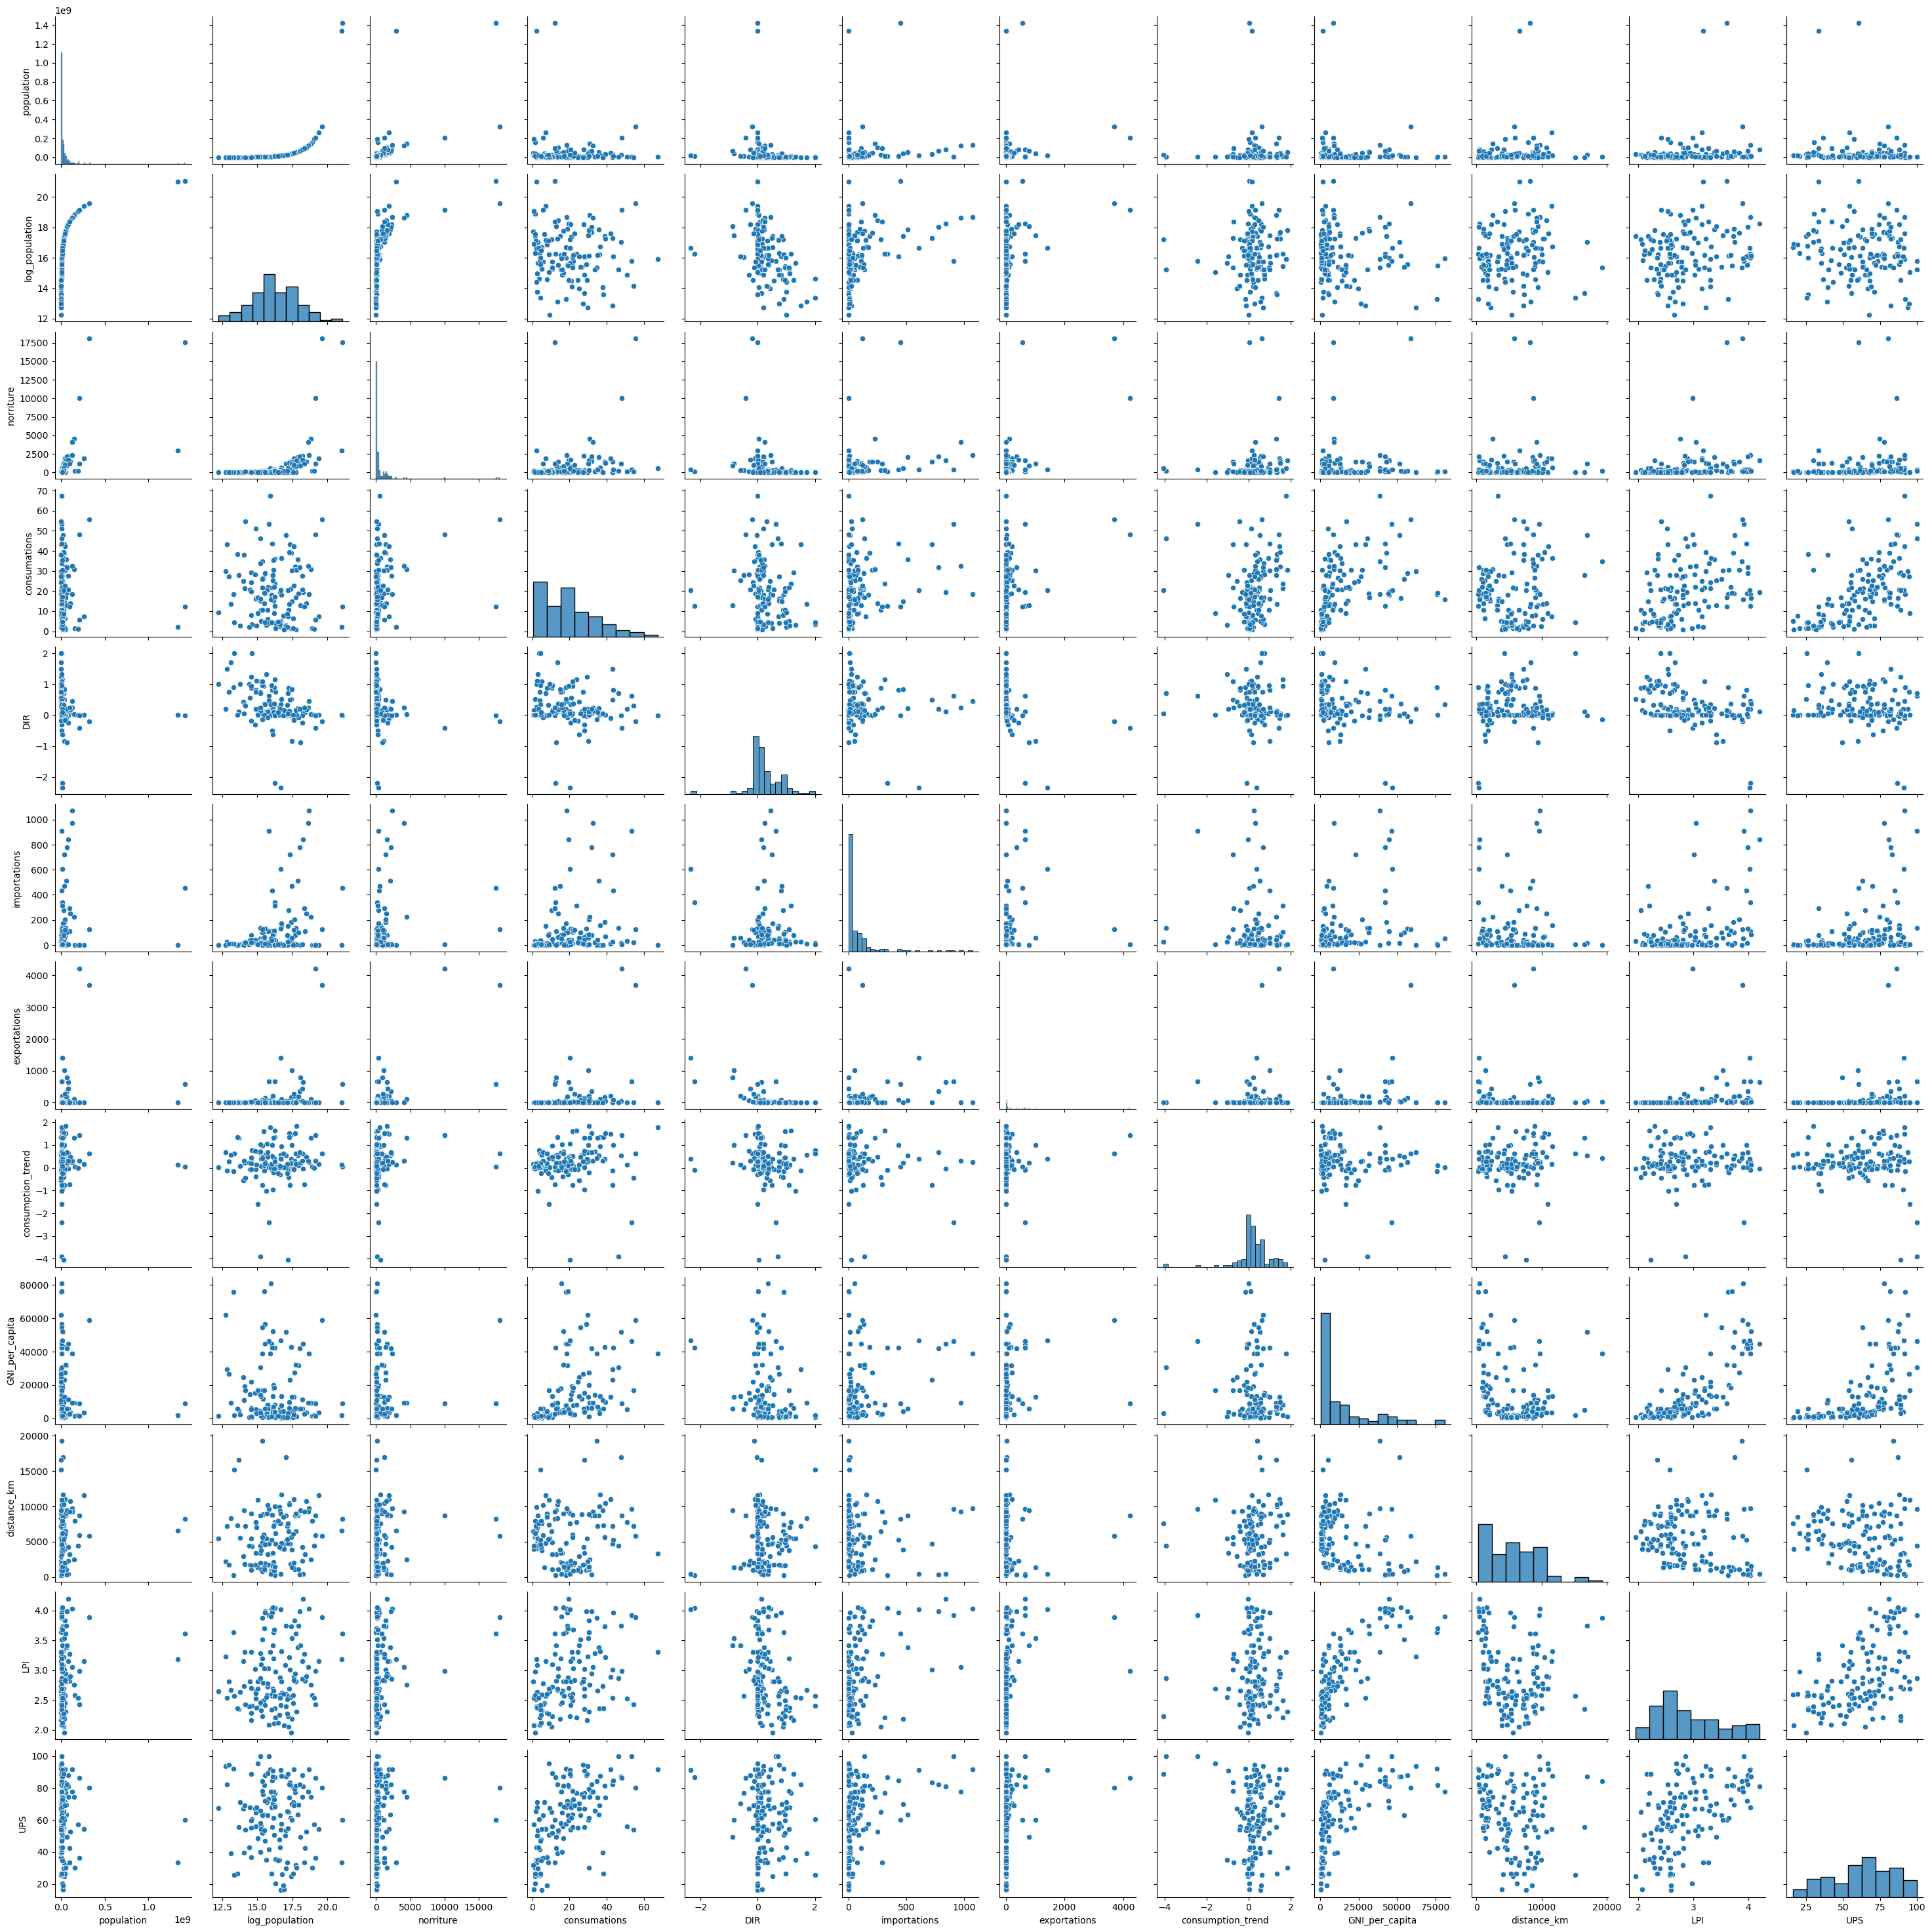

In [156]:
# Faire un pairplot pour visualise chaques variables et leurs correlation
sns.pairplot(df_multi_full.drop(columns="iso3"))

In [ ]:
# Conclusions concernant les variables
print("Conclusions concernant les variables:")
print("Les variables les plus problématiques pour les statistiques multivariables sont \nla population, les importations et les exportations en raison de leur forte asymétrie.\n(et la nourriture, mais cette variable n'a été incluse que dans l'ensemble de données à des fins de comparaison)\n\n")
print("La population sera conservée, faute de variable équivalente. En revanche, les importations et les exportations seront exclues, \ncar elles sont indirectement prises en compte dans le « Dependance Importation Ratio » (DIR), calculé à partir de ces deux variables.\n\n")
print("La variable population, ainsi que les autres variables présentant des valeurs aberrantes importantes, peuvent être traitées soit par: \n1) exclusion des valeurs aberrantes (après analyse), soit par \n2) transformation logarithmique des données.")




Conclusions concernant les variables:
Les variables les plus problématiques pour les statistiques multivariables sont 
la population, les importations et les exportations en raison de leur forte asymétrie.
(et la nourriture, mais cette variable n'a été incluse que dans l'ensemble de données à des fins de comparaison)


La population sera conservée, faute de variable équivalente. En revanche, les importations et les exportations seront exclues, 
car elles sont indirectement prises en compte dans le « Dependance Importation Ratio » (DIR), calculé à partir de ces deux variables.


La variable population, ainsi que les autres variables présentant des valeurs aberrantes importantes, peuvent être traitées soit par: 
1) exclusion des valeurs aberrantes (après analyse), soit par 
2) transformation logarithmique des données.


<div style="border: 2px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 5px; color: RGB(255,255,255); ">4.1.2a - Alternative 1) exclusion des valeurs aberrantes (après analyse). </h3>
</div>

In [159]:
# Examiner les outliers - population
# Exclure les outliers 
mask = df_multi_full["population"] > 1000000000

print("Excluez ces deux valeurs aberrantes, car elles déséquilibrent fortement l'ensemble de données. \n\nDe plus, il s'agit de pays éloignés et peu importants pour une éventuelle expansion du marché des produits biologiques \n(les longs transports ne sont pas très écologiques). \nPar ailleurs, l'Inde ne consomme pas beaucoup de viande/poulet.")
print()

df_multi_red = df_multi_full[~mask] 
df_multi_full[mask] # les deux outliers dans la variable de population


Excluez ces deux valeurs aberrantes, car elles déséquilibrent fortement l'ensemble de données. 

De plus, il s'agit de pays éloignés et peu importants pour une éventuelle expansion du marché des produits biologiques 
(les longs transports ne sont pas très écologiques). 
Par ailleurs, l'Inde ne consomme pas beaucoup de viande/poulet.



,iso3,population,log_population,norriture,consumations,DIR,importations,exportations,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
pays_norm,,,,,,,,,,,,,
"chine, continentale",CHN,1.421022e+09,21.074642,17518.0,12.33,-0.007078,452.0,576.0,0.032619,8830.0,8239.324310,3.61,60.240269
inde,IND,1.338677e+09,21.014947,2965.0,2.22,-0.001349,0.0,4.0,0.144286,1790.0,6600.756276,3.18,33.182133


In [161]:
# Examiner les outliers - DIR
print("Bien qu'ils constituent des valeurs aberrantes (leurs exportations de poulet sont élevées par rapport à leur consommation), \nces pays seront conservés dans l'ensemble de données. \nCeci est dû, d'une part, à la distribution relativement symétrique des données et, d'autre part, au fait qu'il s'agit de pays européens et proches géographiquement, \nqu'il est important de maintenir dans notre analyse.")
print()

df_multi_red[df_multi_red["DIR"] < -1.5] # les deux outliers dans la variable de DIR

Bien qu'ils constituent des valeurs aberrantes (leurs exportations de poulet sont élevées par rapport à leur consommation), 
ces pays seront conservés dans l'ensemble de données. 
Ceci est dû, d'une part, à la distribution relativement symétrique des données et, d'autre part, au fait qu'il s'agit de pays européens et proches géographiquement, 
qu'il est important de maintenir dans notre analyse.



,iso3,population,log_population,norriture,consumations,DIR,importations,exportations,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
pays_norm,,,,,,,,,,,,,
belgique,BEL,11419748.0,16.250855,144.0,12.65,-2.208333,338.0,656.0,-0.088452,42310.0,262.436219,4.04,86.673174
pays-bas,NLD,17021347.0,16.649979,346.0,20.33,-2.341040,608.0,1418.0,0.375357,46710.0,427.900842,4.02,91.121970


In [162]:
# Examiner les outliers - consumation trend
print("Ces valeurs aberrantes sont exclues car elles contribuent à une longue traîne dans la distribution. \n\nLes pays sont géographiquement éloignés et moins susceptibles de correspondre à notre poulet écologique.")
print()

df_multi_red = df_multi_red[~(df_multi_red["consumption_trend"] < -2)]  # exclue les deux outliers
df_multi_full[df_multi_full["consumption_trend"] < -2] # les deux outliers dans la variable de consuation trend (df_multi_full pour les visualiser)


Ces valeurs aberrantes sont exclues car elles contribuent à une longue traîne dans la distribution. 

Les pays sont géographiquement éloignés et moins susceptibles de correspondre à notre poulet écologique.



,iso3,population,log_population,norriture,consumations,DIR,importations,exportations,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
pays_norm,,,,,,,,,,,,,
chine - ras de hong-kong,HKG,7306322.0,15.804251,391.0,53.51,0.624041,907.0,663.0,-2.417738,46380.0,9647.244767,3.92,100.000000
koweit,KWT,4056099.0,15.215732,188.0,46.25,0.707447,137.0,4.0,-3.912381,30650.0,4417.538521,2.86,100.000000
venezuela (republique bolivarienne du),VEN,29402484.0,17.196590,596.0,20.28,0.041946,25.0,0.0,-4.057976,2950.0,7614.818946,2.23,89.028773


In [163]:
# Examiner les outliers - GNI trend
print("Ces valeurs sont à la limite d'être considérées comme aberrantes, mais leur conservation est justifiée: \nles pays sont européens avec une forte economie, et tres importants à conserver dans notre analyse.")
print()

df_multi_red[df_multi_red["GNI_per_capita"] > 70000] # les deux outliers dans la variable de GNI

Ces valeurs sont à la limite d'être considérées comme aberrantes, mais leur conservation est justifiée: 
les pays sont européens avec une forte economie, et tres importants à conserver dans notre analyse.



,iso3,population,log_population,norriture,consumations,DIR,importations,exportations,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
pays_norm,,,,,,,,,,,,,
luxembourg,LUX,591910.0,13.291110,11.0,18.33,0.909091,11.0,1.0,-0.166190,75800.0,289.645983,3.63,92.096377
norvege,NOR,5296326.0,15.482524,101.0,19.05,0.019802,2.0,0.0,0.093214,76230.0,1343.528916,3.70,81.969975
suisse,CHE,8455804.0,15.950364,133.0,15.72,0.353383,51.0,4.0,0.000714,80770.0,436.647780,3.90,77.912627


In [ ]:
# Examiner les outliers - distance_km
print("Ces valeurs aberrantes ne sont pas exclues. Elles contribuent seulement à une légère asymétrie de la distribution. \nDe plus, bien que ces pays soient géographiquement éloignés, ils présentent un profil intéressant au regard des autres variables.")
print()

df_multi_full[df_multi_full["distance_km"] > 15000] # les deux outliers dans la variable de distance (df_multi_full pour les visualiser)

Ces valeurs aberrantes ne sont pas exclues. Elles contribuent seulement à une légère asymétrie de la distribution. 
De plus, bien que ces pays soient géographiquement éloignés, ils présentent un profil intéressant au regard des autres variables.



,iso3,population,log_population,norriture,consumations,DIR,importations,exportations,consumption_trend,GNI_per_capita,distance_km,LPI,UPS,GNI_per_capita_log,distance_km_log,consumations_log
pays_norm,,,,,,,,,,,,,,,,
australie,AUS,24584620.0,17.017632,1171.0,47.65,-0.022203,16.0,42.0,0.526310,51700.0,16919.041468,3.75,87.128093,10.853213,9.736195,3.863883
fidji,FJI,877459.0,13.684786,25.0,28.02,0.120000,3.0,0.0,1.318333,5120.0,16576.823634,2.35,55.740834,8.540910,9.715761,3.332919
iles salomon,SLB,636039.0,13.363015,3.0,4.45,2.000000,6.0,0.0,0.614405,2020.0,15167.289912,2.57,25.383054,7.610853,9.626896,1.492904
nouvelle-zelande,NZL,4702034.0,15.363506,164.0,34.79,-0.134146,1.0,23.0,0.407738,38840.0,19242.284869,3.88,84.170103,10.567206,9.864865,3.549330


In [179]:
# Alternative 1 - sans outliers 
# Reduir le dataset
df_multi_red_red = df_multi_red.drop(columns=["log_population","norriture","importations","exportations"])
df_multi_red_red

,iso3,population,consumations,DIR,consumption_trend,GNI_per_capita,distance_km,LPI,UPS
pays_norm,,,,,,,,,
afghanistan,AFG,36296113.0,1.53,0.527273,-0.038929,530.0,5597.877813,1.95,24.835282
afrique du sud,ZAF,57009756.0,35.69,0.221622,0.532500,5850.0,8654.323509,3.38,63.331108
albanie,ALB,2884169.0,16.36,0.808511,-0.399762,4700.0,1605.053520,2.66,55.980276
algerie,DZA,41389189.0,6.38,0.007576,-0.015833,4440.0,1337.880037,2.45,71.322791
allemagne,DEU,82658409.0,19.47,0.121815,-0.029048,44730.0,440.324090,4.20,80.984254
...,...,...,...,...,...,...,...,...,...
uruguay,URY,3436641.0,9.12,0.000000,-1.585952,16720.0,10936.410144,2.69,95.228824
viet nam,VNM,94600648.0,12.33,0.248714,-0.721429,2680.0,9215.016428,3.27,33.362596
yemen,YEM,27834819.0,8.53,0.329114,-0.230357,880.0,5310.996332,2.27,33.558691


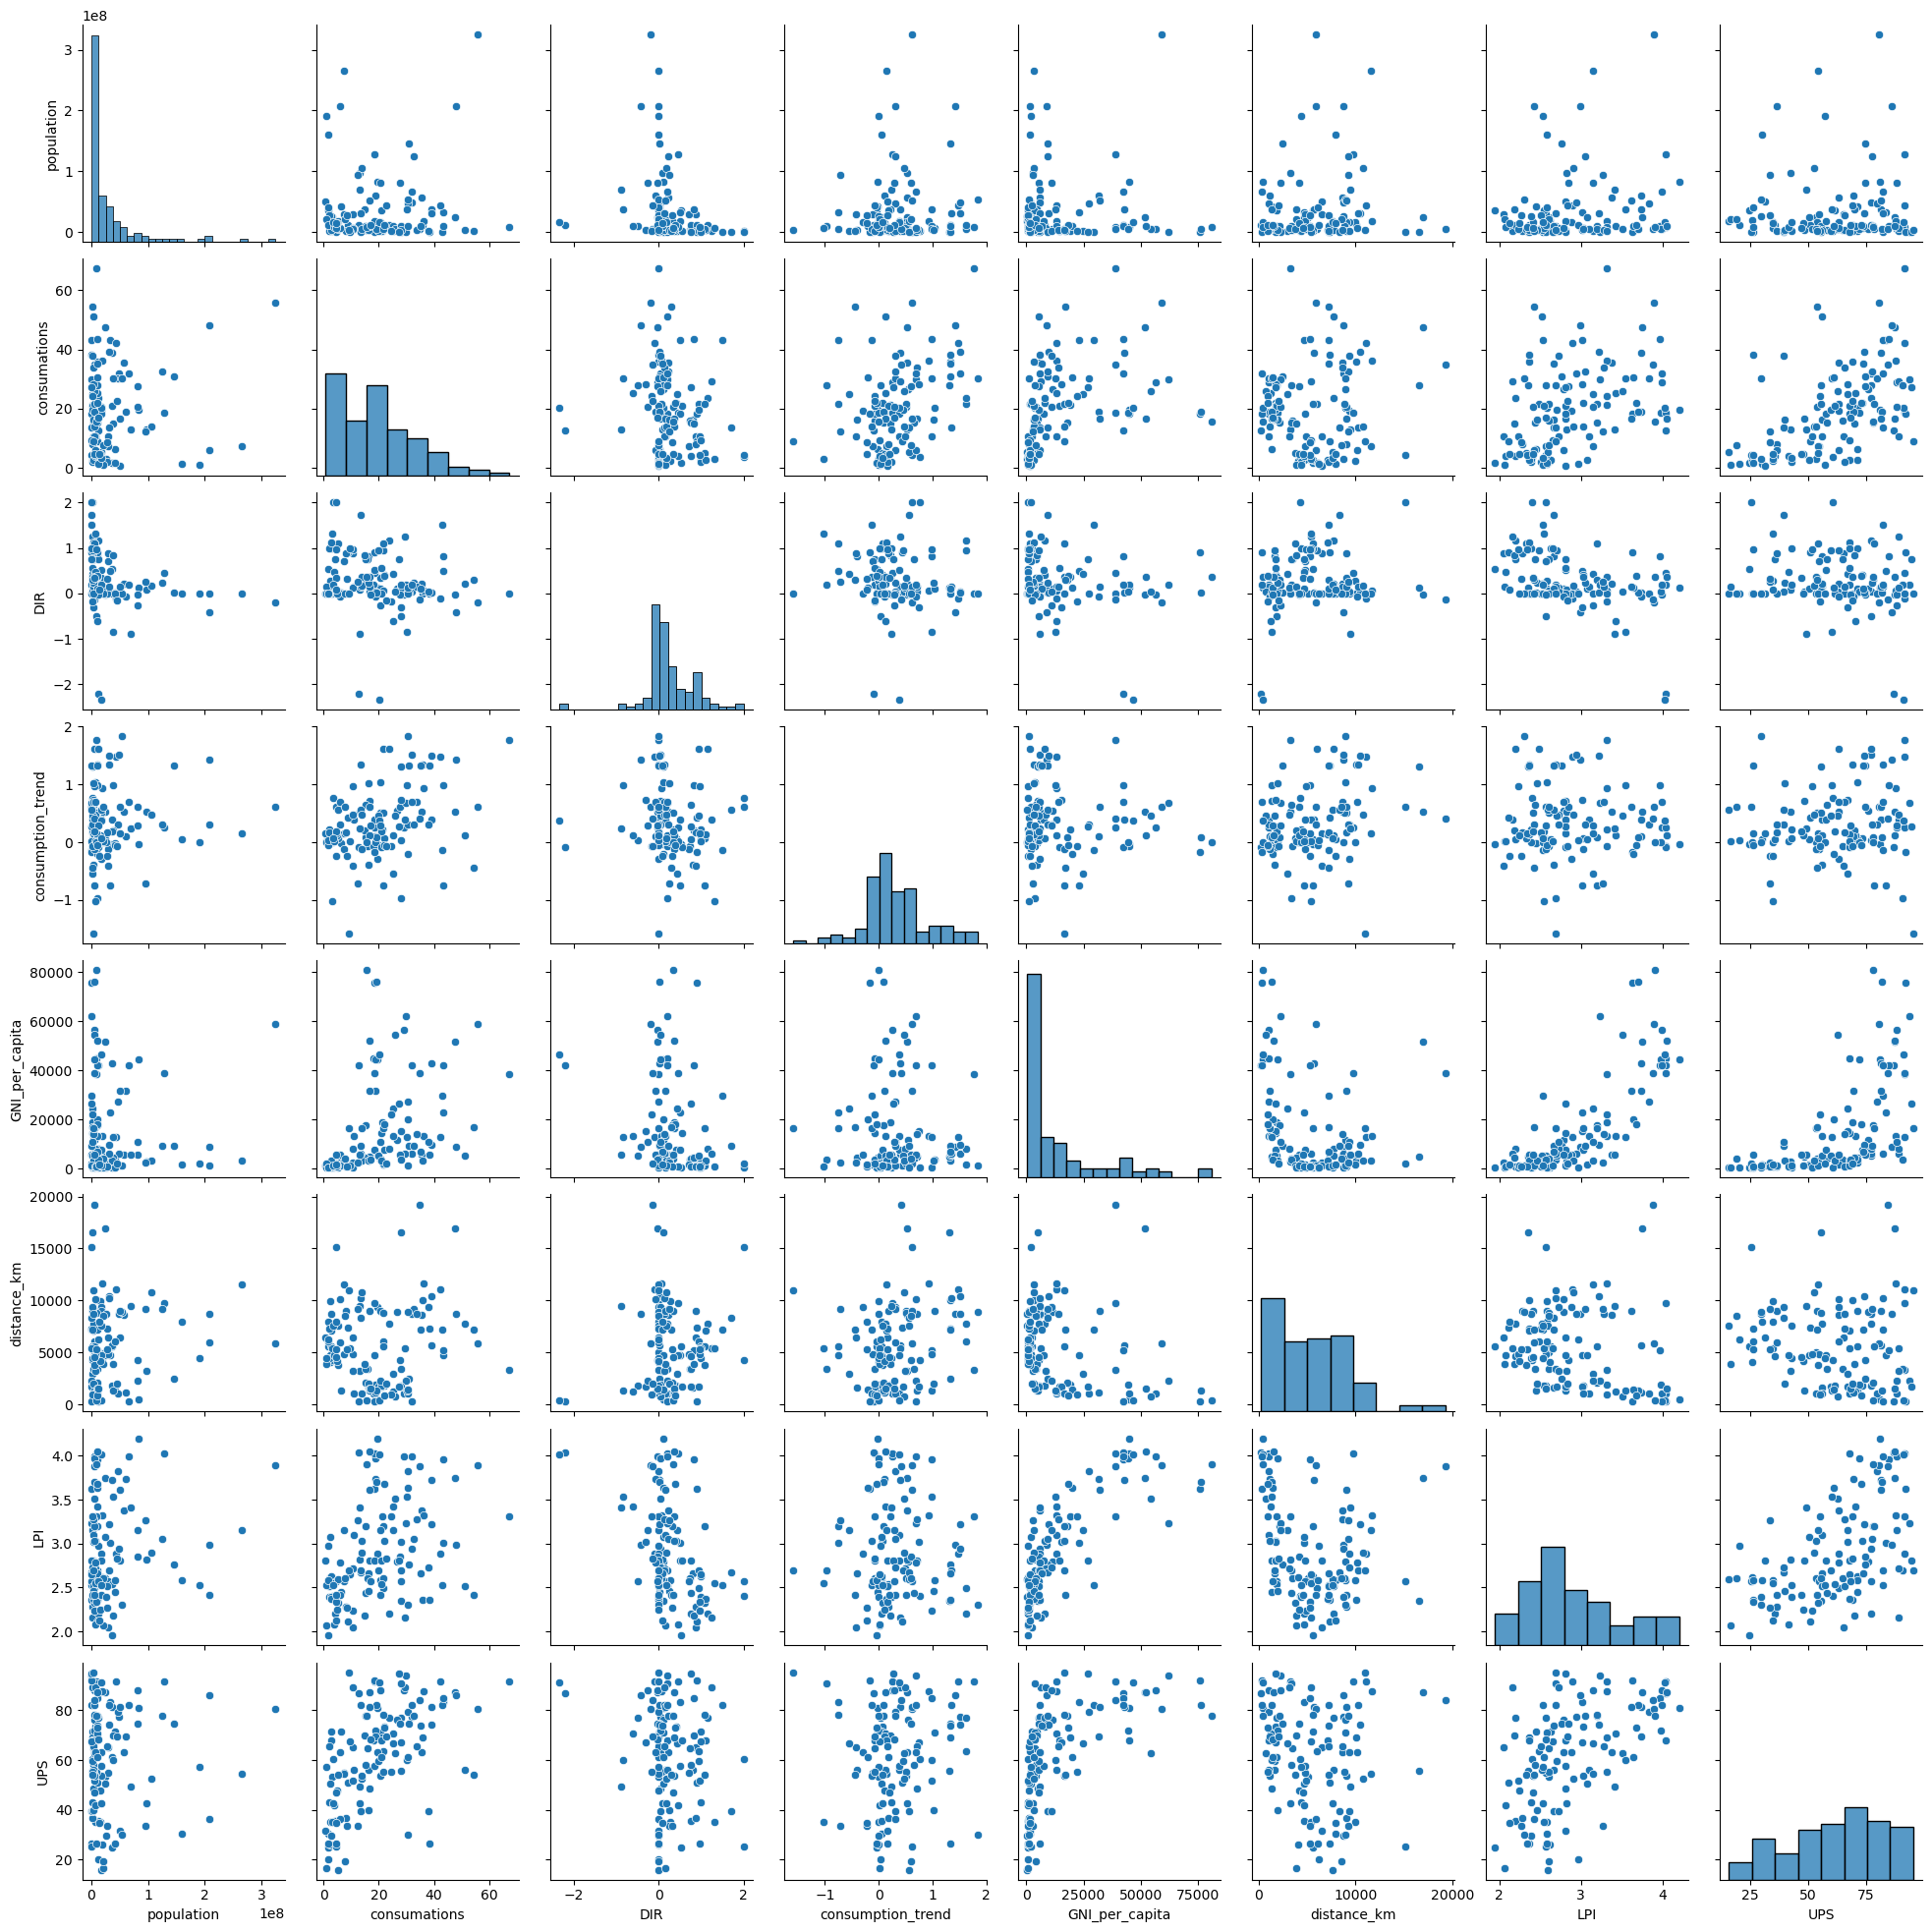

In [180]:
# Faire un pairplot pour visualise chaques variables et leurs correlation apres l'exclusion des outliers
sns.pairplot(df_multi_red_red)

In [168]:
# Enregistrez l'ensemble de données - Alternative 1 
df_multi_red_red.to_csv("Donnees/df_multi_red.csv")

<div style="border: 2px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 5px; color: RGB(255,255,255); ">4.1.2b - Alternative 2) transformation logarithmique des données. </h3>
</div>

In [181]:
# Conserver que les variables d'intérêt principal, et log transform les variables présentant une distribution asymétrique (et qui contenant soeulment des valeurs > 0)
df_multi_log = df_multi_full
# log transformation
df_multi_log["GNI_per_capita_log"] = np.log(df_multi_full["GNI_per_capita"])
df_multi_log["distance_km_log"] = np.log(df_multi_full["distance_km"])
df_multi_log["consumations_log"] = np.log(df_multi_full["consumations"])

# reduir le dataset
df_multi_log_red = df_multi_log.drop(columns=["population","norriture","DIR","importations","exportations","GNI_per_capita","distance_km","consumations"])

df_multi_log_red.head()

,iso3,log_population,consumption_trend,LPI,UPS,GNI_per_capita_log,distance_km_log,consumations_log
pays_norm,,,,,,,,
afghanistan,AFG,17.407221,-0.038929,1.95,24.835282,6.272877,8.630143,0.425268
afrique du sud,ZAF,17.858733,0.532500,3.38,63.331108,8.674197,9.065814,3.574871
albanie,ALB,14.874747,-0.399762,2.66,55.980276,8.455318,7.380912,2.794839
algerie,DZA,17.538530,-0.015833,2.45,71.322791,8.398410,7.198842,1.853168
allemagne,DEU,18.230227,-0.029048,4.20,80.984254,10.708400,6.087511,2.968875


In [182]:
# Examiner les outliers - consumation trend
print("Consumption_trend ne peut être transformée logarithmiquement en raison de ses valeurs négatives, les valeurs aberrantes seront donc exclues, \ncar les pays sont géographiquement éloignés et moins susceptibles de correspondre à notre poulet écologique \n(les longs transports ne sont pas très écologiques).\n\n")
df_multi_log_red[df_multi_log_red["consumption_trend"] < -2] # les deux outliers dans la variable de consuation trend

Consumption_trend ne peut être transformée logarithmiquement en raison de ses valeurs négatives, les valeurs aberrantes seront donc exclues, 
car les pays sont géographiquement éloignés et moins susceptibles de correspondre à notre poulet écologique 
(les longs transports ne sont pas très écologiques).




,iso3,log_population,consumption_trend,LPI,UPS,GNI_per_capita_log,distance_km_log,consumations_log
pays_norm,,,,,,,,
chine - ras de hong-kong,HKG,15.804251,-2.417738,3.92,100.000000,10.744624,9.174428,3.979869
koweit,KWT,15.215732,-3.912381,2.86,100.000000,10.330388,8.393338,3.834061
venezuela (republique bolivarienne du),VEN,17.196590,-4.057976,2.23,89.028773,7.989560,8.937851,3.009635


In [183]:
# Exclure les outliers - consumation trend
df_multi_log_red = df_multi_log_red[~(df_multi_log_red["consumption_trend"] < -2)]    # exclue les deux outliers


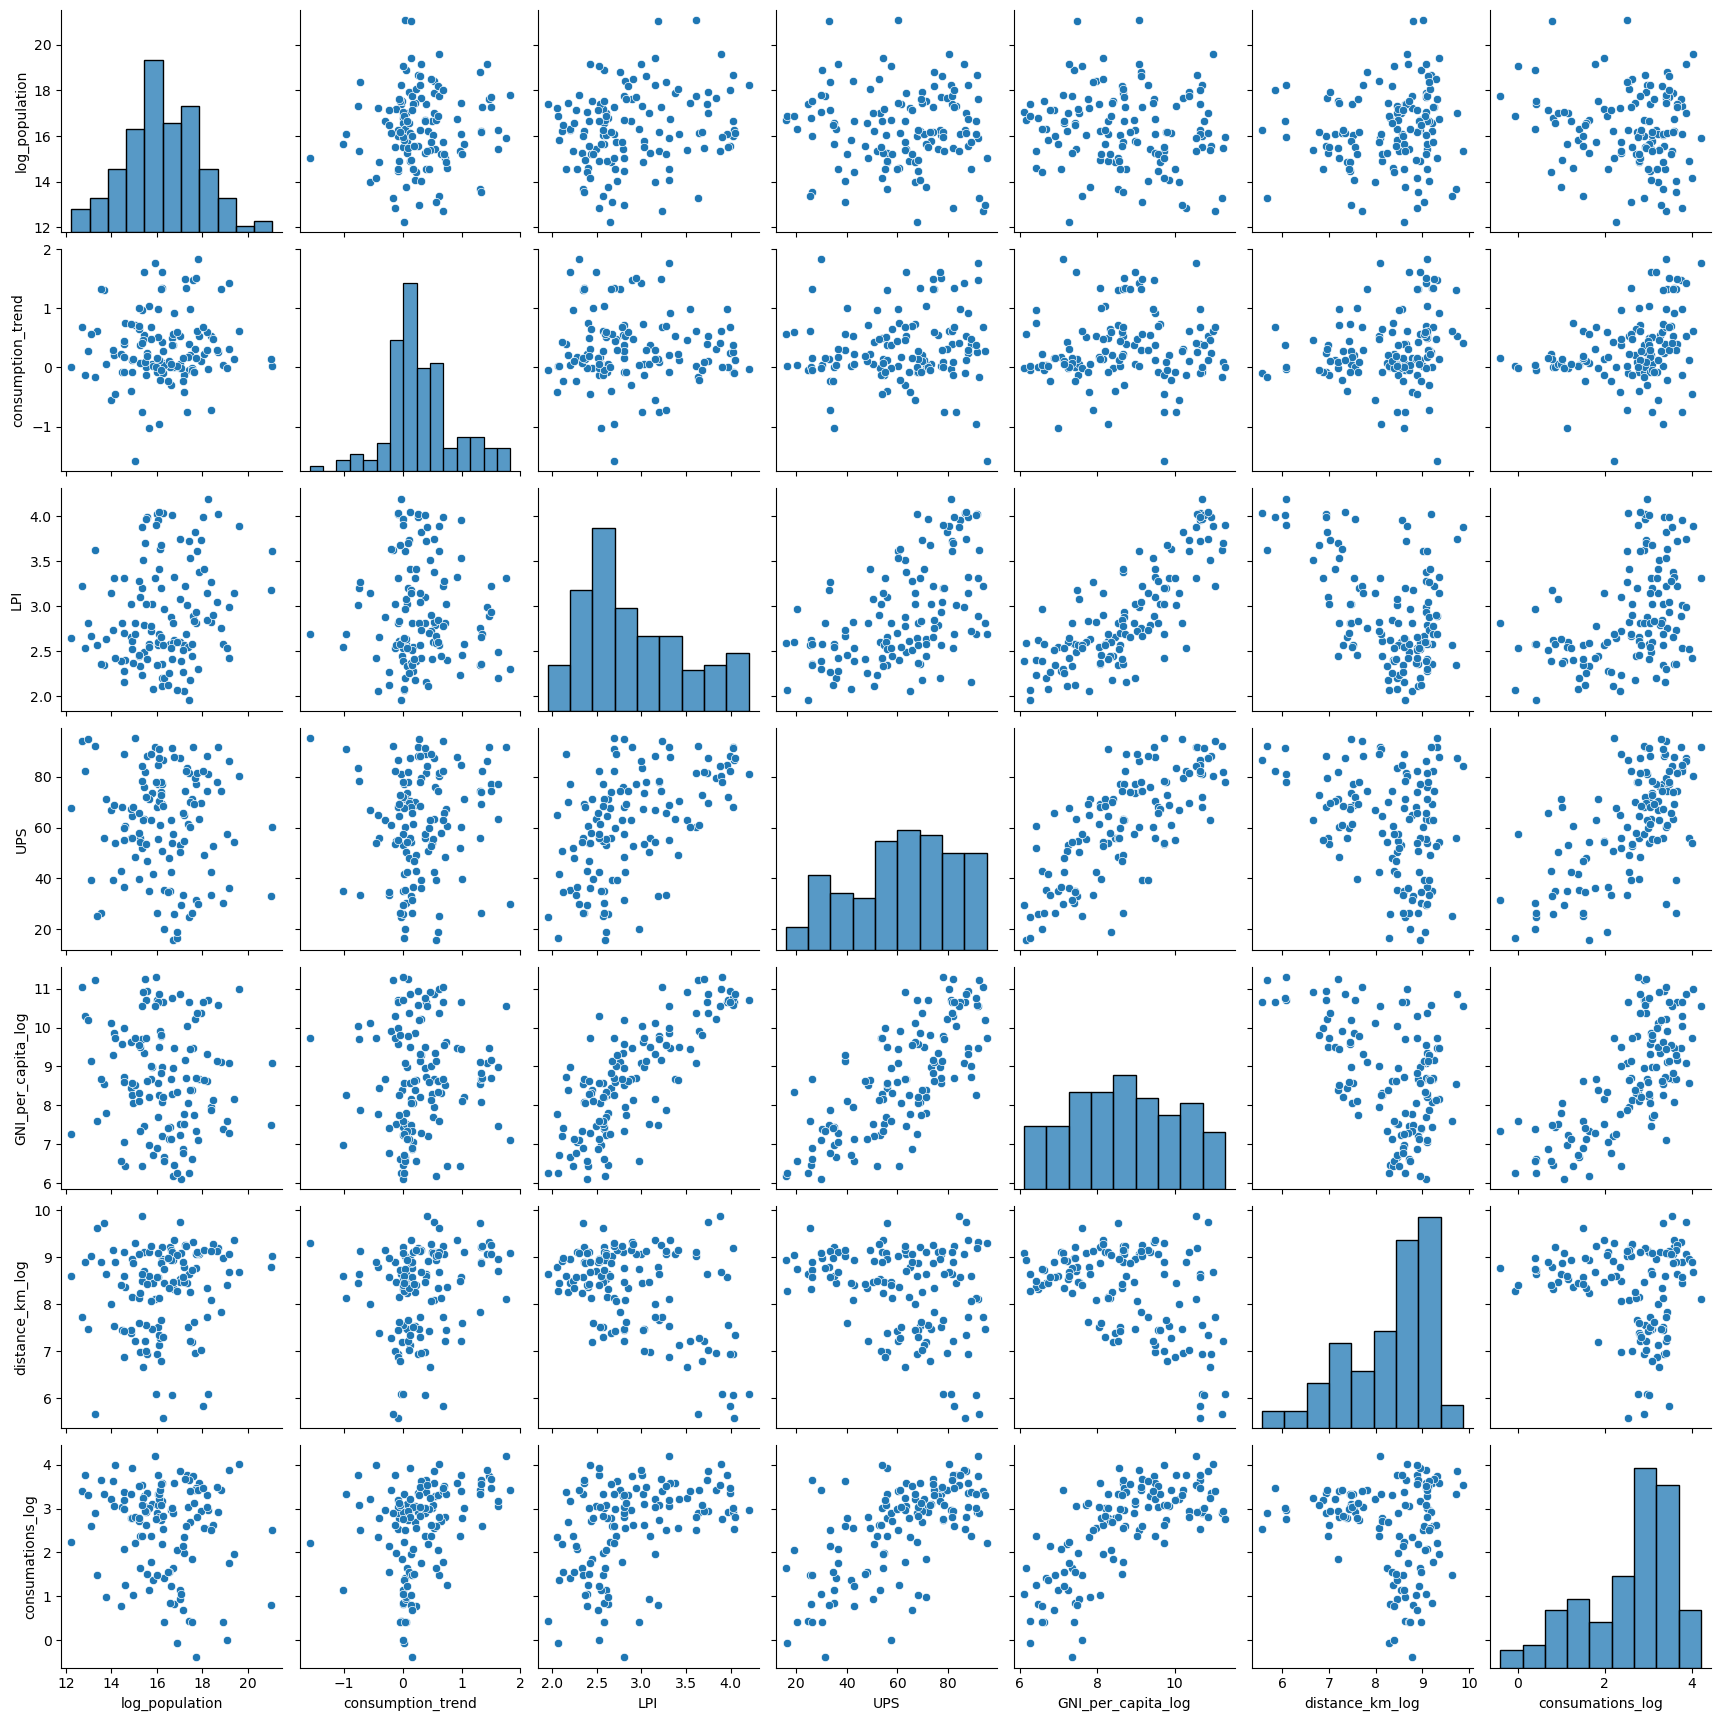

In [184]:
# Faire un pairplot pour visualise chaques variables et leurs correlation
sns.pairplot(df_multi_log_red)

In [185]:
# Enregistrez l'ensemble de données - Alternative 2 
df_multi_log_red.to_csv("Donnees/df_multi_log.csv")


In [ ]:
# Fin du script